> **Escopo deste notebook**  
> Esta entrega contempla exclusivamente a Análise Exploratória de Dados (EDA). Não inclui engenharia de atributos voltada à modelagem, pré-processamento, divisão treino/teste ou treinamento de algoritmos.

**Objetivo analítico**  
Compreender o perfil da base, avaliar a qualidade dos dados, caracterizar o fenômeno de churn, investigar associações entre variáveis e identificar segmentos que merecem atenção do ponto de vista de negócio.

**Base analisada:** `telco_customer_churn.xlsx`  
**Granularidade:** um registro por cliente  
**Target descritivo:** `Churn Value` (1 = cancelou; 0 = permaneceu)

### Como ler os resultados

- Taxa de churn = cancelamentos ÷ total de clientes do grupo analisado.
- Composição dos cancelamentos = distribuição de características **somente entre quem cancelou**. Essas duas métricas respondem perguntas diferentes.
- Os resultados são associações descritivas. Não demonstram causalidade.
- Variáveis registradas após o cancelamento, como `Churn Reason`, são usadas apenas para descrever o evento, nunca como explicação antecedente do comportamento.

## 1. Ambiente e carregamento dos dados

O bloco abaixo procura o arquivo em locais usuais: mesma pasta do notebook, subpasta `data/` ou `/mnt/data/`. Caso esteja em outro local, ajuste `DATA_PATH` manualmente.

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from scipy.stats import chi2_contingency

# Configuração visual consistente
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.0,
    rc={
        "figure.figsize": (10, 5.5),
        "axes.titleweight": "bold",
        "axes.titlesize": 14,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.22,
        "legend.frameon": False,
    },
)

PALETTE = {
    "navy": "#17324D",
    "blue": "#3C78A8",
    "teal": "#2A9D8F",
    "coral": "#E76F51",
    "gold": "#E9C46A",
    "gray": "#7B8794",
    "light": "#EAF0F4",
}
CHURN_COLORS = {0: PALETTE["blue"], 1: PALETTE["coral"]}
STATUS_LABELS = {0: "Permaneceu", 1: "Cancelou"}


raw = pd.read_excel("../data/telco_customer_churn.xlsx")
df = raw.copy()

# Conversão não destrutiva: preserva a coluna original e cria uma versão numérica.
# Células vazias/espaços em Total Charges passam a ser NaN, sem imputação.
df["Total Charges Numeric"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", pd.NA),
    errors="coerce",
)

# Rótulos auxiliares para visualizações (não alteram o target original).
df["Churn Status"] = df["Churn Value"].map(STATUS_LABELS)

print(f"Dimensões: {df.shape[0]:,} linhas × {raw.shape[1]:,} colunas originais")
display(df.head())

Dimensões: 7,043 linhas × 33 colunas originais


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason,Total Charges Numeric,Churn Status
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer,108.15,Cancelou
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Electronic check,70.70,151.65,Yes,1,67,2701,Moved,151.65,Cancelou
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Electronic check,99.65,820.5,Yes,1,86,5372,Moved,820.5,Cancelou
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved,3046.05,Cancelou
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices,5036.3,Cancelou


## 2. Entendimento da estrutura e qualidade dos dados

Antes de interpretar padrões, verificamos granularidade, tipos, unicidade, consistência entre as duas representações do target e ausências. Nesta base, algumas ausências são esperadas por definição: `Churn Reason` não é preenchida para clientes que permaneceram.

In [2]:
# Visão estrutural
estrutura = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "não nulos": df.notna().sum(),
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "valores distintos": df.nunique(dropna=True),
})

display(estrutura.sort_values(["% nulos", "valores distintos"], ascending=[False, False]))

print("\nLinhas duplicadas:", int(df.duplicated().sum()))
print("CustomerID duplicados:", int(df["CustomerID"].duplicated().sum()))
print("CustomerID únicos:", int(df["CustomerID"].nunique()))

,dtype,não nulos,nulos,% nulos,valores distintos
Churn Reason,object,1869,5174,73.46,20
Total Charges Numeric,Float64,7032,11,0.16,6530
CustomerID,object,7043,0,0.00,7043
Total Charges,object,7043,0,0.00,6531
CLTV,int64,7043,0,0.00,3438
Zip Code,int64,7043,0,0.00,1652
Lat Long,object,7043,0,0.00,1652
Latitude,float64,7043,0,0.00,1652
Longitude,float64,7043,0,0.00,1651
Monthly Charges,float64,7043,0,0.00,1585



Linhas duplicadas: 0
CustomerID duplicados: 0
CustomerID únicos: 7043


In [3]:
# Colunas constantes e variáveis de cardinalidade elevada
nunique = df[raw.columns].nunique(dropna=False)
constantes = nunique[nunique <= 1].index.tolist()
altas_cardinalidades = nunique[nunique >= 100].sort_values(ascending=False)

print("Colunas constantes na base:", constantes)
print("\nVariáveis com pelo menos 100 valores distintos:")
display(altas_cardinalidades.to_frame("valores distintos"))

Colunas constantes na base: ['Count', 'Country', 'State']

Variáveis com pelo menos 100 valores distintos:


,valores distintos
CustomerID,7043
Total Charges,6531
CLTV,3438
Zip Code,1652
Lat Long,1652
Latitude,1652
Longitude,1651
Monthly Charges,1585
City,1129


### 2.1 Dicionário resumido das variáveis

| Grupo | Variáveis | Significado / observação |
|---|---|---|
| Identificação | `CustomerID`, `Count` | Identificador do cliente e contador de registros. `Count` é constante nesta extração. |
| Geografia | `Country`, `State`, `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude` | Localização residencial; a base observada está concentrada em um único estado/país. |
| Perfil | `Gender`, `Senior Citizen`, `Partner`, `Dependents` | Características demográficas e familiares. |
| Relacionamento | `Tenure Months` | Meses de relacionamento até o fim do trimestre de referência. |
| Serviços | `Phone Service`, `Multiple Lines`, `Internet Service`, `Online Security`, `Online Backup`, `Device Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies` | Produtos e serviços contratados. Algumas categorias `No internet service` / `No phone service` indicam não aplicabilidade. |
| Contrato e cobrança | `Contract`, `Paperless Billing`, `Payment Method`, `Monthly Charges`, `Total Charges` | Condições contratuais, meio de pagamento e valores cobrados. |
| Resultado | `Churn Label`, `Churn Value` | Duas representações do mesmo target: texto e indicador binário. |
| Variáveis derivadas por terceiros | `Churn Score`, `CLTV` | Score preditivo IBM SPSS Modeler e CLTV calculado por fórmulas corporativas, segundo o dicionário fornecido. |
| Pós-evento | `Churn Reason` | Motivo informado para o cancelamento; preenchido para clientes que cancelaram. |


In [4]:
# Verificações direcionadas para os principais pontos de qualidade
label_map = {"No": 0, "Yes": 1}
label_as_value = df["Churn Label"].map(label_map)
consistencia_target = bool(label_as_value.notna().all() and label_as_value.eq(df["Churn Value"]).all())

missing_total = int(df["Total Charges Numeric"].isna().sum())
missing_total_tenure_zero = bool(
    (df.loc[df["Total Charges Numeric"].isna(), "Tenure Months"] == 0).all()
)
missing_reason_churn = int(
    df.loc[df["Churn Value"] == 1, "Churn Reason"].isna().sum()
)
missing_reason_active = int(
    df.loc[df["Churn Value"] == 0, "Churn Reason"].isna().sum()
)

quality_checks = pd.Series({
    "Churn Label corresponde a Churn Value": consistencia_target,
    "Total Charges ausente (após conversão numérica)": missing_total,
    "Todos os Total Charges ausentes têm Tenure = 0": missing_total_tenure_zero,
    "Churn Reason ausente entre cancelados": missing_reason_churn,
    "Churn Reason ausente entre clientes ativos": missing_reason_active,
})
display(quality_checks.to_frame("resultado"))

,resultado
Churn Label corresponde a Churn Value,True
Total Charges ausente (após conversão numérica),11
Todos os Total Charges ausentes têm Tenure = 0,True
Churn Reason ausente entre cancelados,0
Churn Reason ausente entre clientes ativos,5174


### 2.2 Tratamento interpretativo de valores ausentes

- **`Total Charges`:** a conversão numérica identifica 11 valores vazios. Todos estão associados a `Tenure Months = 0`. O arquivo não comprova que esses clientes tenham pago uma mensalidade completa; por isso, esta EDA mantém o valor como ausente e não o substitui por `Monthly Charges`.
- **`Churn Reason`:** os nulos dos clientes ativos são ausência estrutural, e não uma falha de coleta equivalente a um campo faltante para todos. A análise dos motivos será feita somente entre os clientes com `Churn Value = 1`.
- Não foram encontrados registros duplicados nem IDs repetidos na extração analisada. A checagem é refeita no código para permanecer auditável.

## 3. Visão executiva da base

Esta seção resume dimensão, volume de cancelamentos, taxa geral e características básicas da distribuição do target.

In [5]:
n_total = len(df)
n_churn = int(df["Churn Value"].sum())
n_retained = int((df["Churn Value"] == 0).sum())
churn_rate = df["Churn Value"].mean()

kpis = [
    ("Clientes", f"{n_total:,}"),
    ("Cancelamentos", f"{n_churn:,}"),
    ("Clientes ativos", f"{n_retained:,}"),
    ("Taxa de churn", f"{churn_rate:.1%}"),
]
html = "<div style='display:grid;grid-template-columns:repeat(4,minmax(130px,1fr));gap:12px;margin:10px 0 18px 0;'>"
for label, value in kpis:
    html += (
        "<div style='background:#F2F6F9;border-left:4px solid #2A9D8F;"
        "padding:14px 16px;border-radius:8px;'>"
        f"<div style='font-size:12px;color:#52616B'>{label}</div>"
        f"<div style='font-size:24px;font-weight:700;color:#17324D'>{value}</div></div>"
    )
html += "</div>"
display(HTML(html))

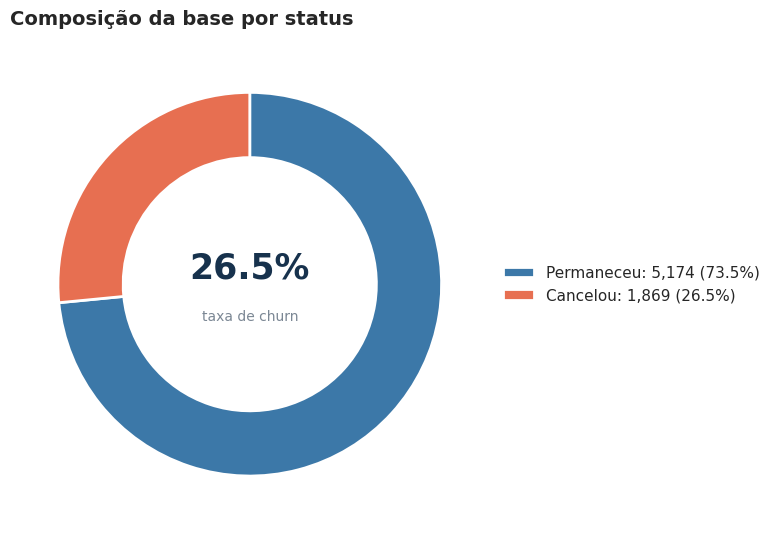

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
counts = df["Churn Status"].value_counts().reindex(["Permaneceu", "Cancelou"])
colors = [PALETTE["blue"], PALETTE["coral"]]
wedges, _ = ax.pie(
    counts,
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"width": 0.34, "edgecolor": "white", "linewidth": 2},
)
ax.text(0, 0.08, f"{churn_rate:.1%}", ha="center", va="center", fontsize=25, weight="bold", color=PALETTE["navy"])
ax.text(0, -0.17, "taxa de churn", ha="center", va="center", fontsize=10, color=PALETTE["gray"])
ax.legend(wedges, [f"{k}: {v:,} ({v/n_total:.1%})" for k, v in counts.items()], loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title("Composição da base por status", loc="left", pad=14)
plt.tight_layout()
plt.show()

### Leitura executiva

A base apresenta desbalanceamento moderado: clientes que cancelaram representam aproximadamente 26,5% dos registros. A taxa geral será usada como referência descritiva nas próximas seções; grupos acima dela apresentam incidência observada maior, mas isso não implica causalidade.

## 4. Perfil dos clientes e distribuição das variáveis

A exploração univariada ajuda a identificar a composição da população analisada e possíveis categorias raras. Para variáveis de serviço, categorias como `No internet service` são mantidas como categorias próprias, pois representam não aplicabilidade e não devem ser confundidas com uma resposta negativa.

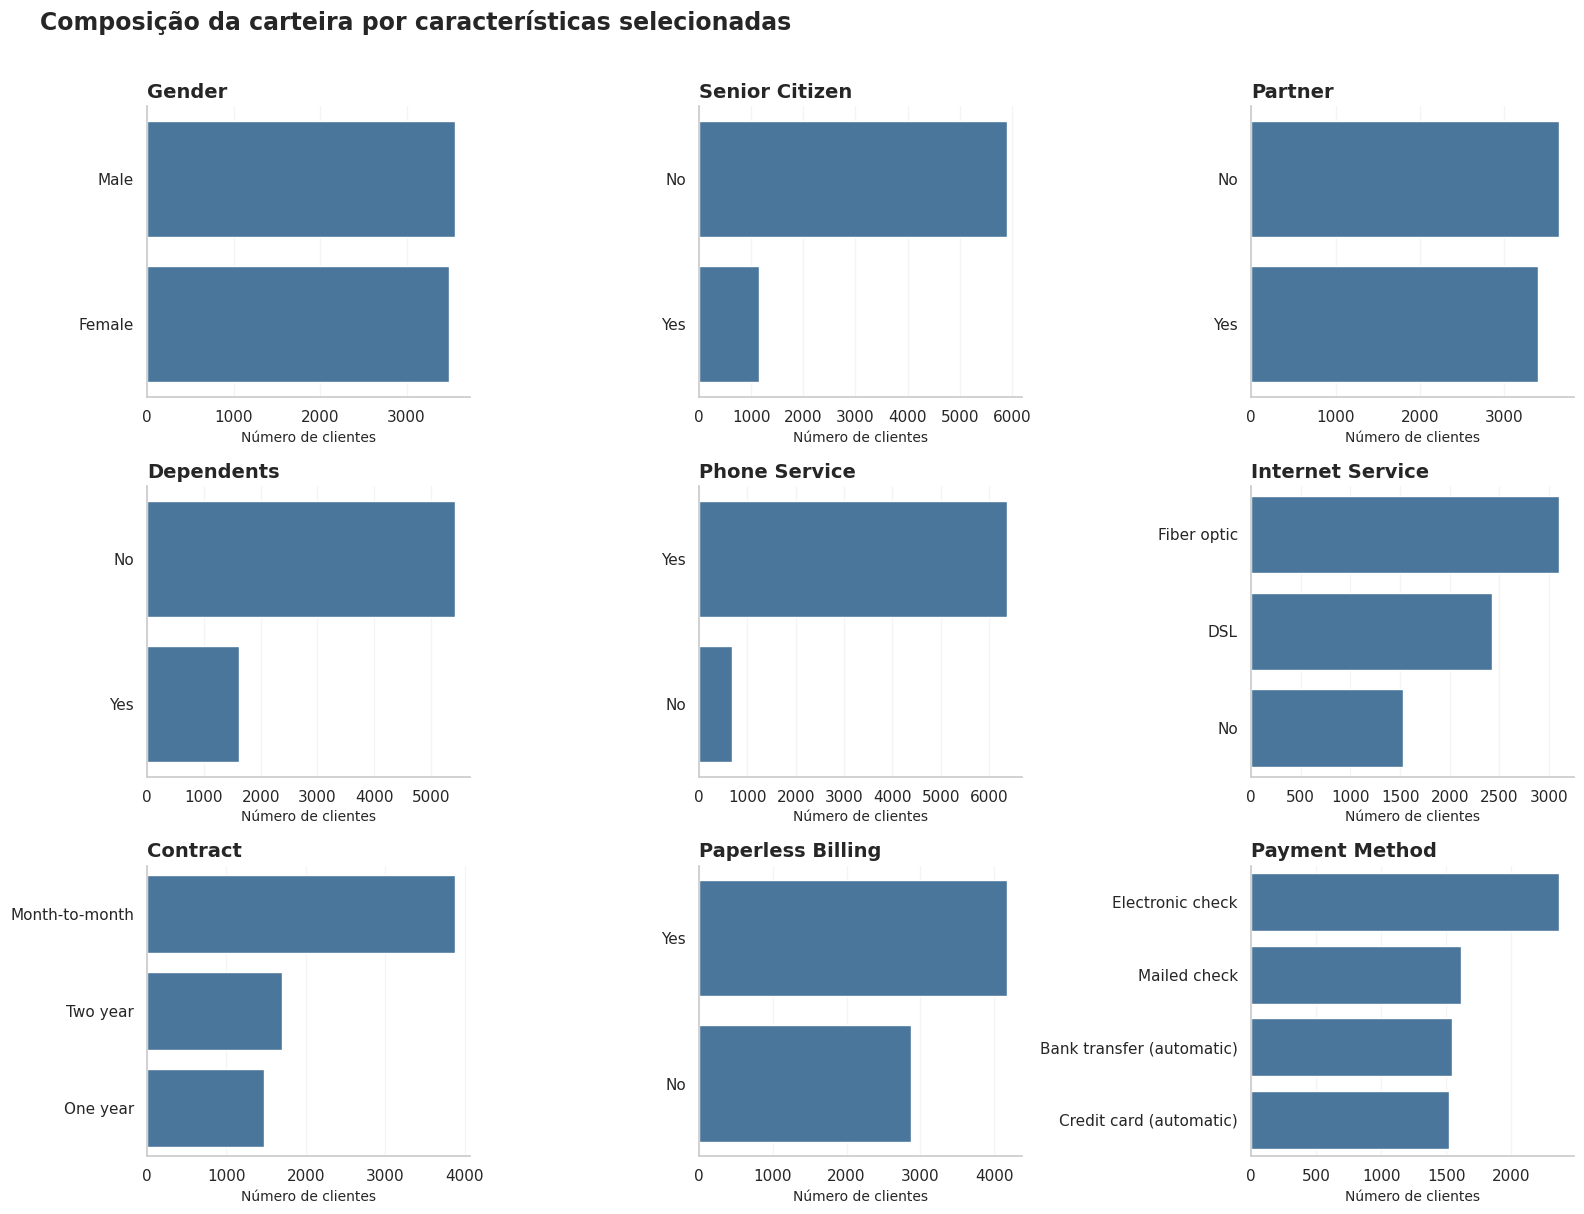

In [7]:
perfil_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Internet Service", "Contract", "Paperless Billing", "Payment Method"
]

ncols = 3
nrows = int(np.ceil(len(perfil_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4.0))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, perfil_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, color=PALETTE["blue"], ax=ax)
    ax.set_title(col, loc="left")
    ax.set_xlabel("Número de clientes")
    ax.set_ylabel("")
    ax.xaxis.grid(True, alpha=0.2)
for ax in axes[len(perfil_cols):]:
    ax.remove()
fig.suptitle("Composição da carteira por características selecionadas", x=0.03, y=1.01, ha="left", fontsize=17, weight="bold")
plt.tight_layout()
plt.show()

,count,média,desvio-padrão,min,5%,25%,mediana,75%,95%,max
Tenure Months,7043.0,32.371149,24.559481,0.0,1.0,9.0,29.0,55.0,72.0,72.0
Monthly Charges,7043.0,64.761692,30.090047,18.25,19.65,35.5,70.35,89.85,107.4,118.75
Total Charges Numeric,7032.0,2283.300441,2266.771362,18.8,49.605,401.45,1397.475,3794.7375,6923.59,8684.8
CLTV,7043.0,4400.295755,1183.057152,2003.0,2296.0,3469.0,4527.0,5380.5,6087.0,6500.0
Churn Score,7043.0,58.699418,21.525131,5.0,24.0,40.0,61.0,75.0,94.0,100.0


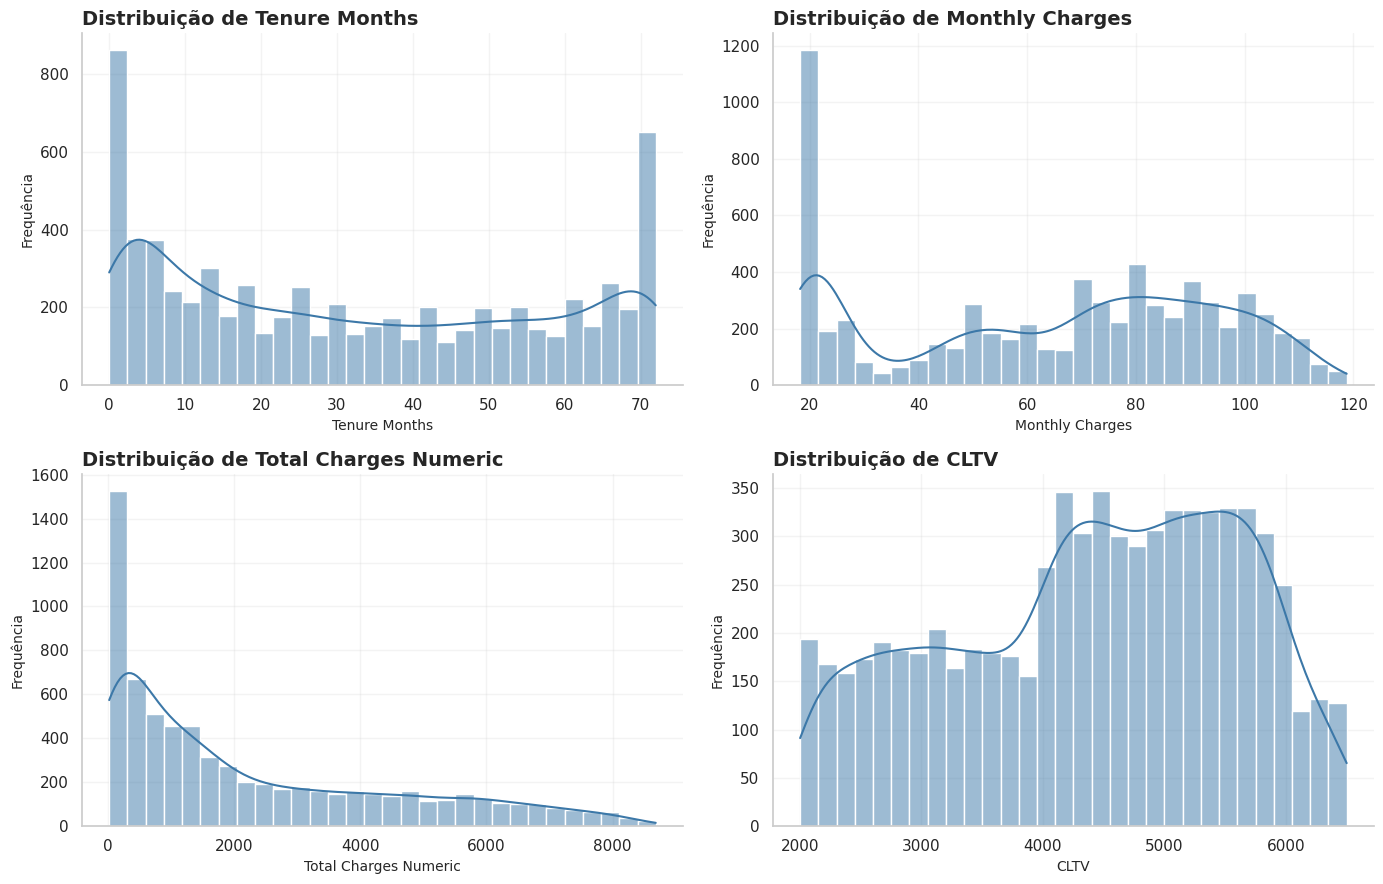

In [8]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges Numeric", "CLTV", "Churn Score"]
num_summary = df[num_cols].describe(percentiles=[.05, .25, .50, .75, .95]).T
num_summary = num_summary.rename(columns={"50%": "mediana", "mean": "média", "std": "desvio-padrão"})
display(num_summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ["Tenure Months", "Monthly Charges", "Total Charges Numeric", "CLTV"]):
    sns.histplot(data=df, x=col, bins=30, kde=True, color=PALETTE["blue"], ax=ax)
    ax.set_title(f"Distribuição de {col}", loc="left")
    ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

## 5. Churn por variáveis categóricas

Para cada categoria, o gráfico apresenta a **taxa de churn dentro do grupo**, acompanhada pelo tamanho da amostra e intervalo de confiança de 95% de Wilson. O intervalo ajuda a evitar leituras excessivamente confiantes em grupos pequenos.

In [9]:
def wilson_interval(successes, total, z=1.96):
    """Intervalo de confiança de Wilson para uma proporção binomial."""
    if total == 0:
        return np.nan, np.nan
    p = successes / total
    denom = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denom
    half = (z * np.sqrt((p * (1 - p) / total) + z**2 / (4 * total**2))) / denom
    return max(0, center - half), min(1, center + half)


def churn_summary(data, group_col, min_n=1):
    """Tabela de volume, cancelamentos, taxa de churn e IC95% por categoria."""
    out = (
        data.groupby(group_col, dropna=False, observed=False)["Churn Value"]
        .agg(clientes="size", cancelamentos="sum", taxa_churn="mean")
        .reset_index()
    )
    cis = out.apply(
        lambda r: wilson_interval(int(r["cancelamentos"]), int(r["clientes"])), axis=1
    )
    out["ic95_inf"] = [x[0] for x in cis]
    out["ic95_sup"] = [x[1] for x in cis]
    out = out[out["clientes"] >= min_n].copy()
    return out.sort_values("taxa_churn", ascending=False)


def plot_churn_rate(data, group_col, min_n=1, order_by_rate=True, figsize=None):
    summary = churn_summary(data, group_col, min_n=min_n)
    if summary.empty:
        print(f"Sem grupos com pelo menos {min_n} observações em {group_col}.")
        return summary
    if order_by_rate:
        summary = summary.sort_values("taxa_churn", ascending=True)
    else:
        summary = summary.sort_values(group_col)
    labels = summary[group_col].astype(str).tolist()
    y = np.arange(len(summary))
    rates = summary["taxa_churn"].to_numpy()
    lower = rates - summary["ic95_inf"].to_numpy()
    upper = summary["ic95_sup"].to_numpy() - rates
    if figsize is None:
        figsize = (10, max(4, 0.48 * len(summary) + 1.5))
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(y, rates * 100, color=PALETTE["blue"], alpha=0.92)
    ax.errorbar(rates * 100, y, xerr=np.vstack([lower, upper]) * 100, fmt="none", ecolor=PALETTE["navy"], capsize=3, lw=1.2)
    ax.axvline(churn_rate * 100, color=PALETTE["coral"], ls="--", lw=1.5, label=f"Taxa geral: {churn_rate:.1%}")
    ax.set_yticks(y, labels)
    ax.set_xlabel("Taxa de churn (%)")
    ax.set_ylabel("")
    ax.set_title(f"Taxa de churn por {group_col}", loc="left", pad=12)
    ax.legend(loc="lower right")
    ax.set_xlim(left=0, right=max(100, (summary["ic95_sup"].max() * 100) + 5))
    for yi, (_, row) in enumerate(summary.iterrows()):
        ax.text(row["ic95_sup"] * 100 + 1, yi, f"{row['taxa_churn']:.1%} · n={int(row['clientes']):,}", va="center", fontsize=8.5, color=PALETTE["navy"])
    plt.tight_layout()
    plt.show()
    return summary.sort_values("taxa_churn", ascending=False)


Contract


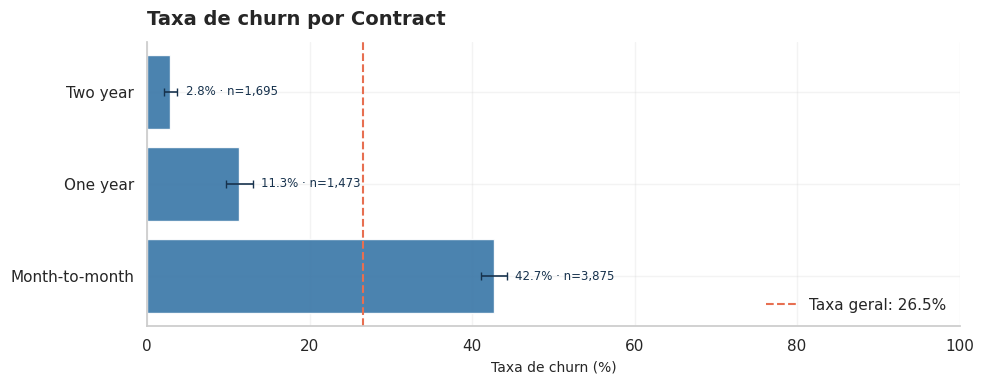

,Contract,clientes,cancelamentos,taxa_churn_pct,ic95
0,Month-to-month,3875,1655,42.71,41.2% – 44.3%
1,One year,1473,166,11.27,9.8% – 13.0%
2,Two year,1695,48,2.83,2.1% – 3.7%



Payment Method


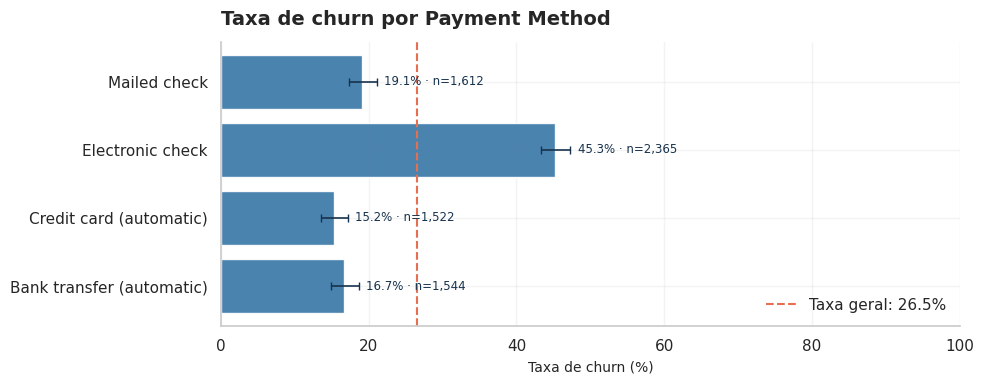

,Payment Method,clientes,cancelamentos,taxa_churn_pct,ic95
2,Electronic check,2365,1071,45.29,43.3% – 47.3%
3,Mailed check,1612,308,19.11,17.3% – 21.1%
0,Bank transfer (automatic),1544,258,16.71,14.9% – 18.7%
1,Credit card (automatic),1522,232,15.24,13.5% – 17.1%



Internet Service


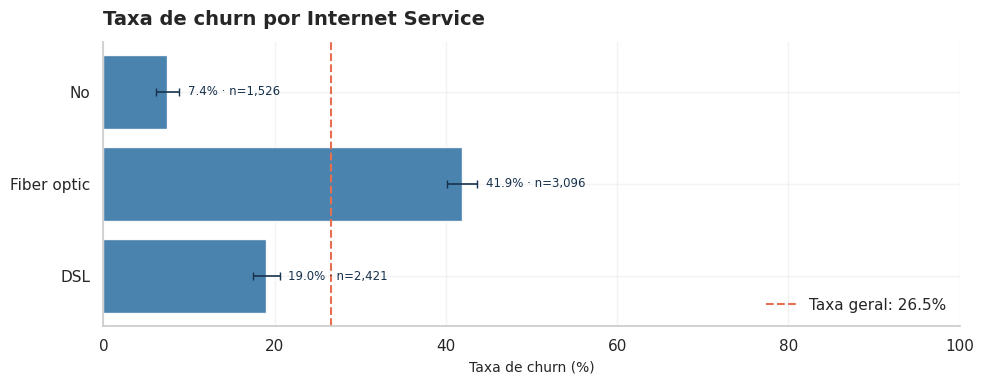

,Internet Service,clientes,cancelamentos,taxa_churn_pct,ic95
1,Fiber optic,3096,1297,41.89,40.2% – 43.6%
0,DSL,2421,459,18.96,17.4% – 20.6%
2,No,1526,113,7.40,6.2% – 8.8%



Paperless Billing


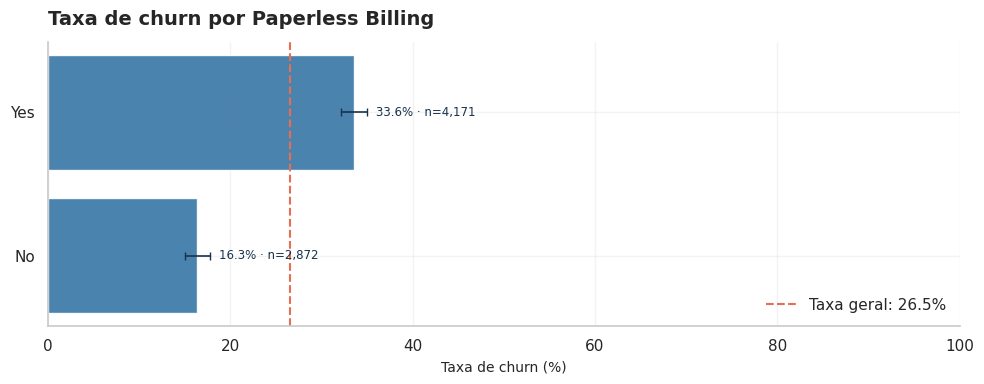

,Paperless Billing,clientes,cancelamentos,taxa_churn_pct,ic95
1,Yes,4171,1400,33.57,32.1% – 35.0%
0,No,2872,469,16.33,15.0% – 17.7%


In [10]:
# Contrato, forma de pagamento, tipo de internet e faturamento digital
for col in ["Contract", "Payment Method", "Internet Service", "Paperless Billing"]:
    print(f"\n{col}")
    summary = plot_churn_rate(df, col, min_n=20, order_by_rate=False)
    display(summary.assign(
        taxa_churn_pct=(summary["taxa_churn"] * 100).round(2),
        ic95=(summary["ic95_inf"].map(lambda x: f"{x:.1%}") + " – " + summary["ic95_sup"].map(lambda x: f"{x:.1%}"))
    )[[col, "clientes", "cancelamentos", "taxa_churn_pct", "ic95"]])


Senior Citizen


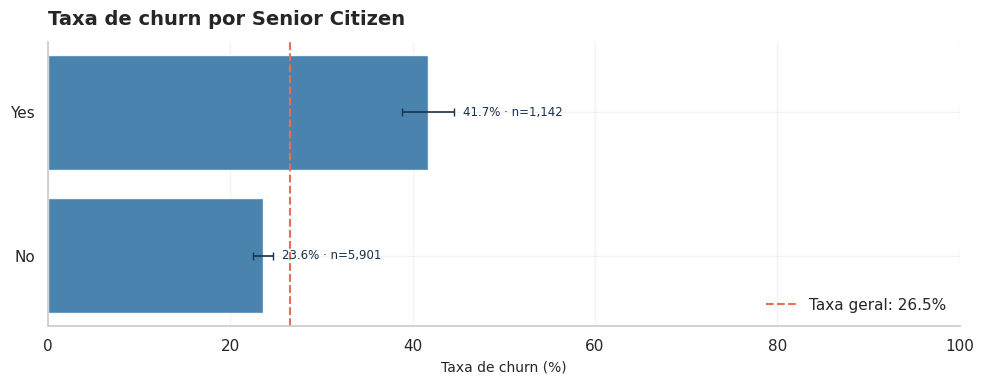


Dependents


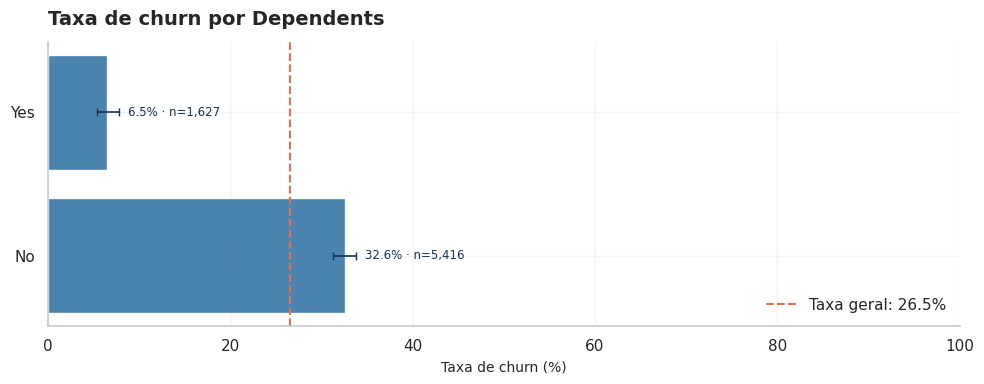


Partner


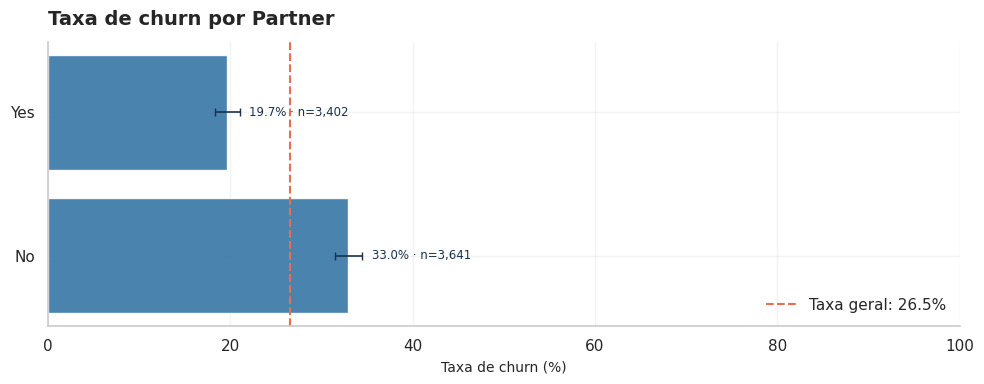


Gender


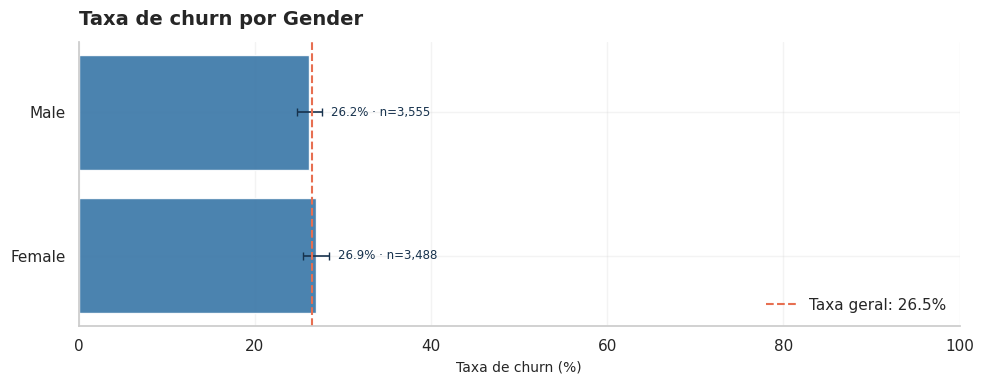

In [11]:
# Perfil demográfico e familiar
for col in ["Senior Citizen", "Dependents", "Partner", "Gender"]:
    print(f"\n{col}")
    plot_churn_rate(df, col, min_n=20, order_by_rate=False)


Phone Service


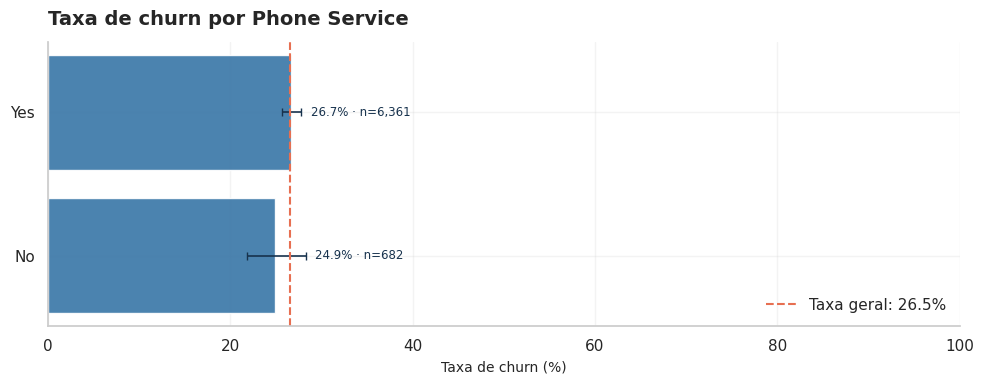


Multiple Lines


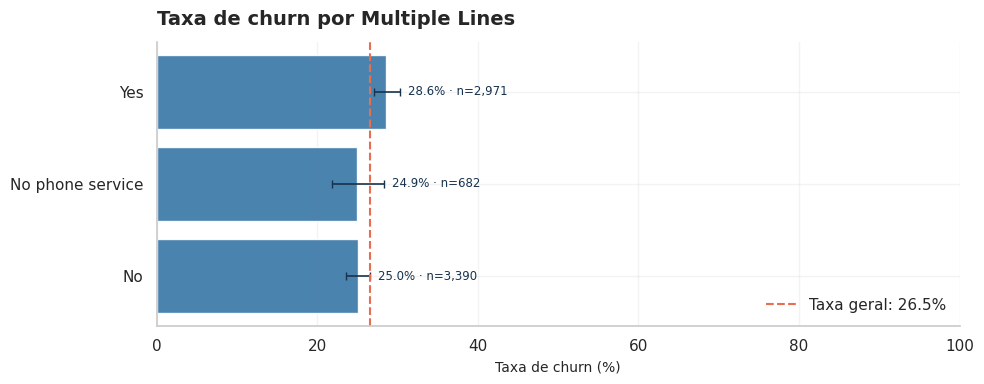

In [12]:
# Serviço telefônico e linhas múltiplas
for col in ["Phone Service", "Multiple Lines"]:
    print(f"\n{col}")
    plot_churn_rate(df, col, min_n=20, order_by_rate=False)

### Leitura desta seção

A taxa deve ser lida junto do volume (`n`). Uma categoria com taxa alta e poucos clientes pode ter intervalo de confiança amplo. Já uma categoria numerosa, mesmo com uma diferença percentual menor, pode representar volume relevante de cancelamentos.

## 6. Variáveis numéricas versus churn

Comparamos distribuições e estatísticas-resumo entre quem permaneceu e quem cancelou. O boxplot é usado como leitura de mediana, dispersão e valores extremos; ele não deve ser interpretado isoladamente como evidência causal.

Tenure Months                ... Churn Score              
                     count   mean median  ...        mean median    std
Churn Status                              ...                          
Cancelou              1869  17.98   10.0  ...       82.51   82.0  10.33
Permaneceu            5174  37.57   38.0  ...       50.10   50.0  17.70

[2 rows x 20 columns]

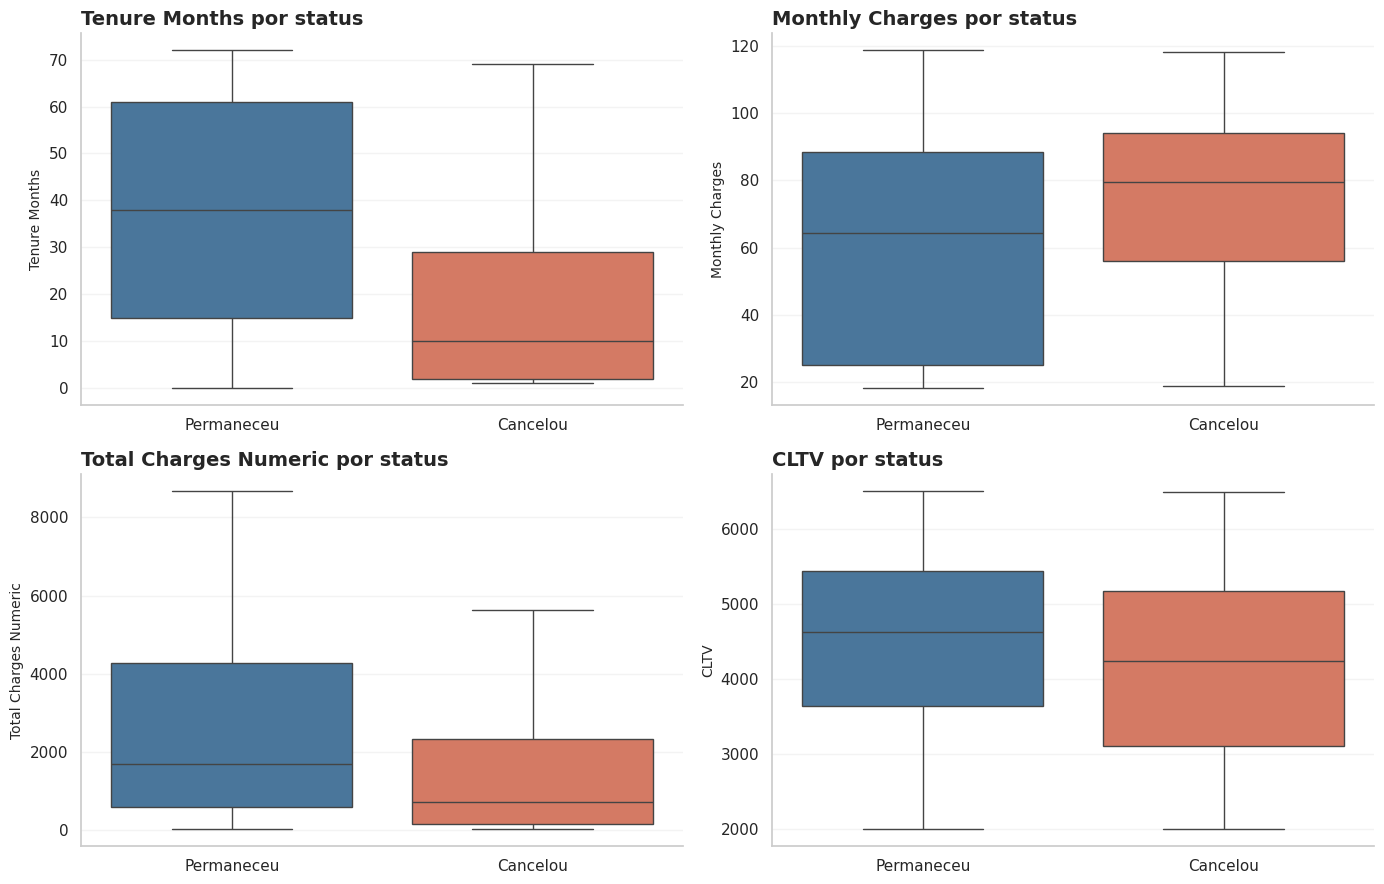

In [13]:
num_compare = ["Tenure Months", "Monthly Charges", "Total Charges Numeric", "CLTV", "Churn Score"]
summary_num = (
    df.groupby("Churn Status")[num_compare]
    .agg(["count", "mean", "median", "std"])
)
display(summary_num.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.flat, ["Tenure Months", "Monthly Charges", "Total Charges Numeric", "CLTV"]):
    sns.boxplot(
        data=df, x="Churn Status", y=col,
        order=["Permaneceu", "Cancelou"],
        hue="Churn Status", dodge=False,
        palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]},
        showfliers=False, legend=False, ax=ax,
    )
    ax.set_title(f"{col} por status", loc="left")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

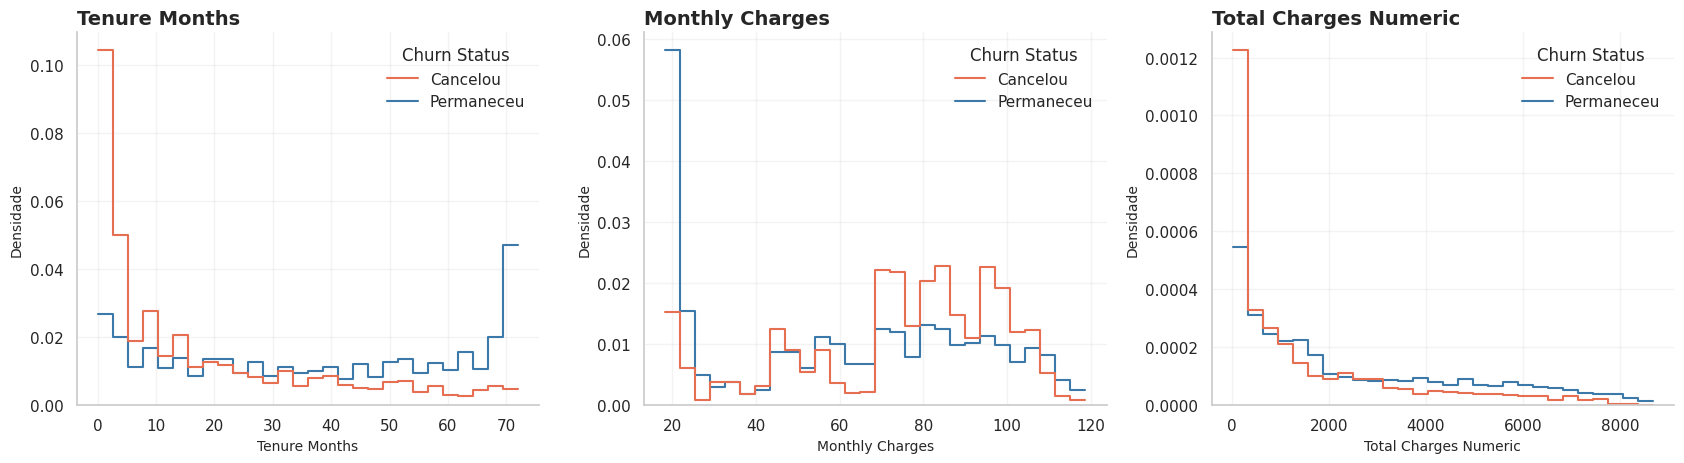

In [14]:
# Distribuições sobrepostas: leitura da forma e da região de maior concentração
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col in zip(axes, ["Tenure Months", "Monthly Charges", "Total Charges Numeric"]):
    sns.histplot(
        data=df, x=col, hue="Churn Status", stat="density", common_norm=False,
        bins=28, element="step", fill=False, palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]},
        ax=ax,
    )
    ax.set_title(col, loc="left")
    ax.set_ylabel("Densidade")
plt.tight_layout()
plt.show()

## 7. Tempo de relacionamento e contrato

A análise mês a mês pode oscilar quando há poucos clientes em determinado mês. Para obter uma leitura mais estável, agrupamos o tempo de relacionamento em faixas. Em seguida, cruzamos tenure e contrato para observar como a taxa varia entre segmentos.

> **Limite interpretativo:** esta é uma fotografia transversal da carteira no trimestre de referência. Não é uma análise de sobrevivência e não mede diretamente o tempo até o evento.

,Tenure Band,clientes,cancelamentos,taxa_churn,ic95_inf,ic95_sup,taxa_churn_pct
0,0–6,1481,784,0.529372,0.503908,0.554685,52.94
1,7–12,705,253,0.358865,0.324310,0.394950,35.89
2,13–24,1024,294,0.287109,0.260235,0.315575,28.71
3,25–36,832,180,0.216346,0.189705,0.245595,21.63
4,37–48,762,145,0.190289,0.163998,0.219687,19.03
5,49–60,832,120,0.144231,0.121992,0.169740,14.42
6,61–72,1407,93,0.066098,0.054261,0.080298,6.61


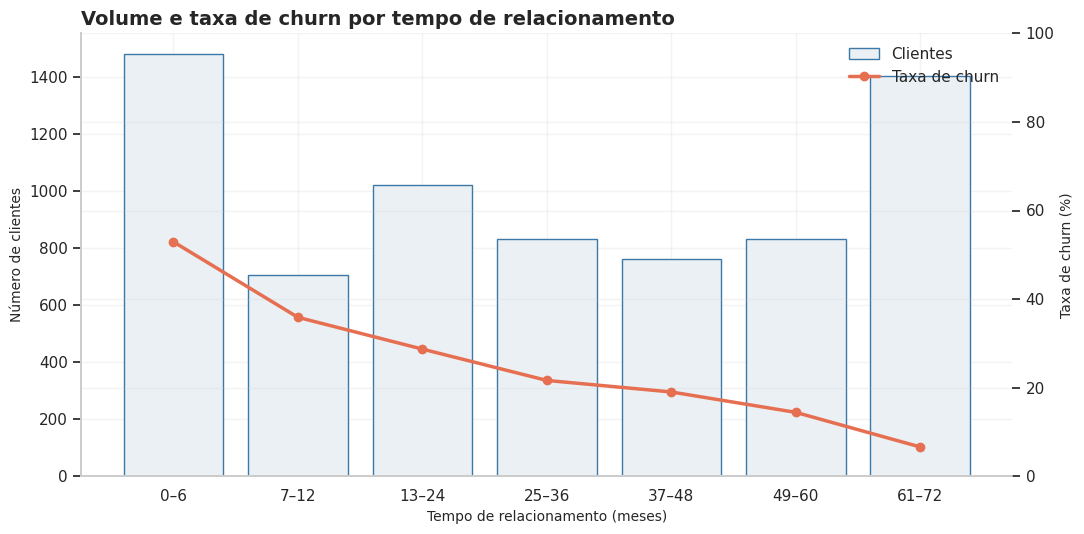

In [15]:
tenure_bins = [-1, 6, 12, 24, 36, 48, 60, 72]
tenure_labels = ["0–6", "7–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
df["Tenure Band"] = pd.cut(df["Tenure Months"], bins=tenure_bins, labels=tenure_labels)

tenure_summary = churn_summary(df, "Tenure Band")
# Reordena pelas faixas definidas, não pela taxa.
tenure_summary["Tenure Band"] = pd.Categorical(tenure_summary["Tenure Band"], categories=tenure_labels, ordered=True)
tenure_summary = tenure_summary.sort_values("Tenure Band")
display(tenure_summary.assign(taxa_churn_pct=(tenure_summary["taxa_churn"] * 100).round(2)))

fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax1.bar(tenure_summary["Tenure Band"].astype(str), tenure_summary["clientes"], color=PALETTE["light"], edgecolor=PALETTE["blue"], label="Clientes")
ax1.set_ylabel("Número de clientes")
ax1.set_xlabel("Tempo de relacionamento (meses)")
ax2 = ax1.twinx()
ax2.plot(tenure_summary["Tenure Band"].astype(str), tenure_summary["taxa_churn"] * 100, color=PALETTE["coral"], marker="o", lw=2.5, label="Taxa de churn")
ax2.set_ylabel("Taxa de churn (%)")
ax2.set_ylim(0, 100)
ax1.set_title("Volume e taxa de churn por tempo de relacionamento", loc="left")
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper right")
plt.tight_layout()
plt.show()

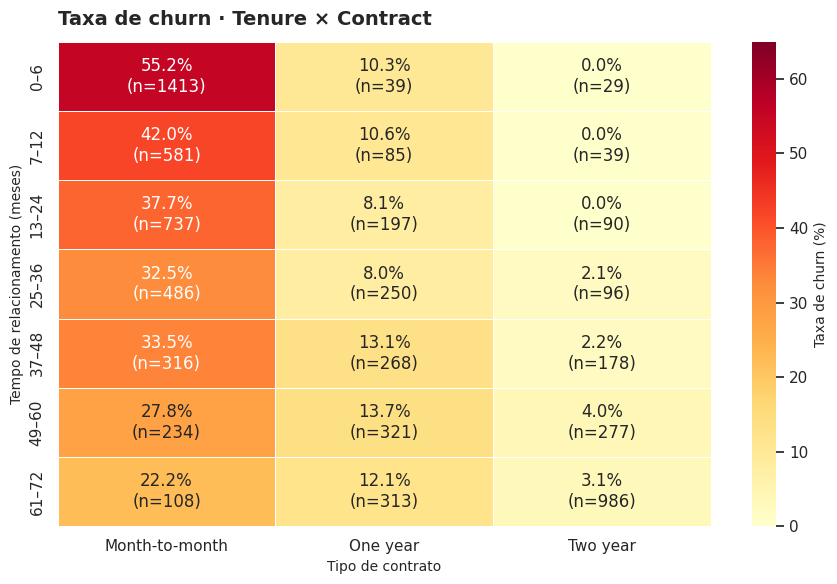

In [16]:
# Heatmap: taxa de churn por faixa de tenure e tipo de contrato.
# Células com menos de 20 clientes são mascaradas para reduzir instabilidade visual.
ct = df.pivot_table(index="Tenure Band", columns="Contract", values="Churn Value", aggfunc="mean", observed=False)
ct_n = df.pivot_table(index="Tenure Band", columns="Contract", values="Churn Value", aggfunc="size", observed=False)
ct = ct.reindex(tenure_labels)
ct_n = ct_n.reindex(tenure_labels)
annot = ct.mul(100).round(1).astype(str) + "%\n(n=" + ct_n.fillna(0).astype(int).astype(str) + ")"
mask = ct_n < 20
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(ct * 100, annot=annot, fmt="", cmap="YlOrRd", vmin=0, vmax=65, linewidths=.6, linecolor="white", mask=mask, cbar_kws={"label": "Taxa de churn (%)"}, ax=ax)
ax.set_title("Taxa de churn · Tenure × Contract", loc="left", pad=12)
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Tempo de relacionamento (meses)")
plt.tight_layout()
plt.show()

## 8. Interações entre produtos, contrato e pagamento

Esta seção aprofunda relações que podem ficar ocultas na análise univariada. Os heatmaps apresentam taxa de churn **dentro de cada combinação** e informam o tamanho de cada célula.

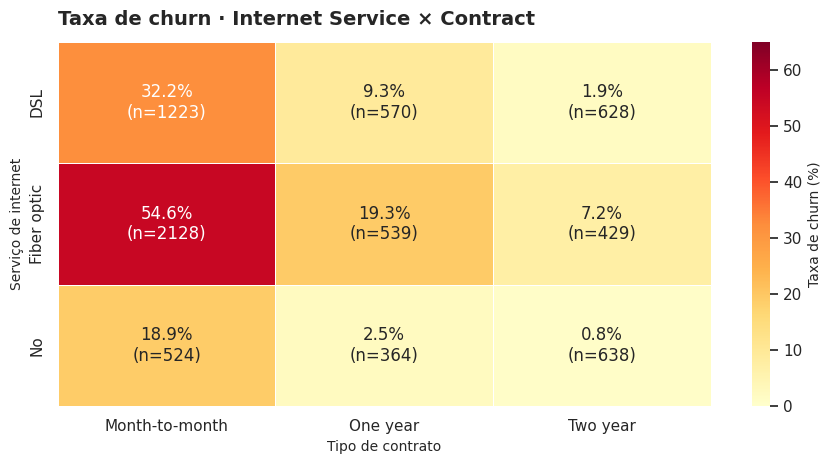

In [17]:
# Internet Service × Contract
rate_ic = df.pivot_table(index="Internet Service", columns="Contract", values="Churn Value", aggfunc="mean")
count_ic = df.pivot_table(index="Internet Service", columns="Contract", values="Churn Value", aggfunc="size")
annot_ic = rate_ic.mul(100).round(1).astype(str) + "%\n(n=" + count_ic.astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(rate_ic * 100, annot=annot_ic, fmt="", cmap="YlOrRd", vmin=0, vmax=65, linewidths=.6, linecolor="white", cbar_kws={"label": "Taxa de churn (%)"}, ax=ax)
ax.set_title("Taxa de churn · Internet Service × Contract", loc="left", pad=12)
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Serviço de internet")
plt.tight_layout()
plt.show()

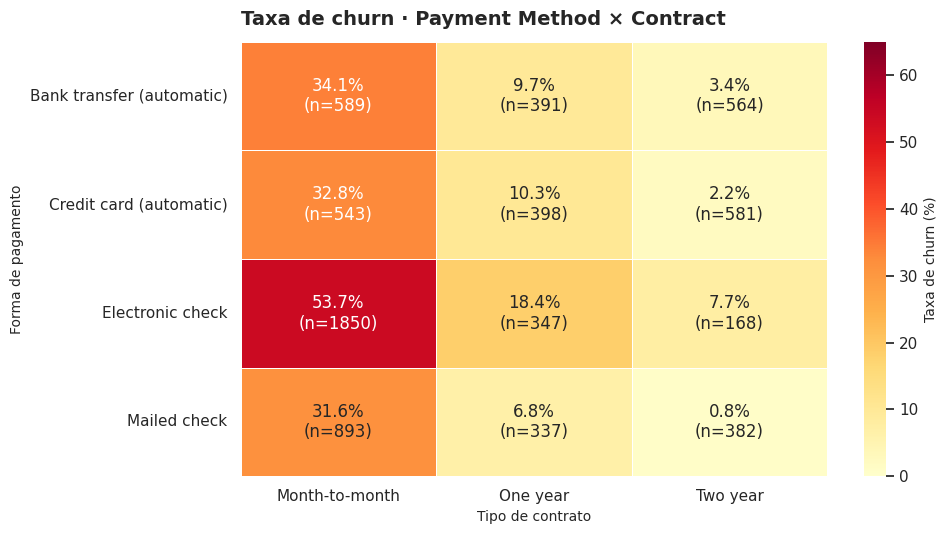

In [18]:
# Payment Method × Contract
rate_pc = df.pivot_table(index="Payment Method", columns="Contract", values="Churn Value", aggfunc="mean")
count_pc = df.pivot_table(index="Payment Method", columns="Contract", values="Churn Value", aggfunc="size")
annot_pc = rate_pc.mul(100).round(1).astype(str) + "%\n(n=" + count_pc.astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(rate_pc * 100, annot=annot_pc, fmt="", cmap="YlOrRd", vmin=0, vmax=65, linewidths=.6, linecolor="white", cbar_kws={"label": "Taxa de churn (%)"}, ax=ax)
ax.set_title("Taxa de churn · Payment Method × Contract", loc="left", pad=12)
ax.set_xlabel("Tipo de contrato")
ax.set_ylabel("Forma de pagamento")
plt.tight_layout()
plt.show()

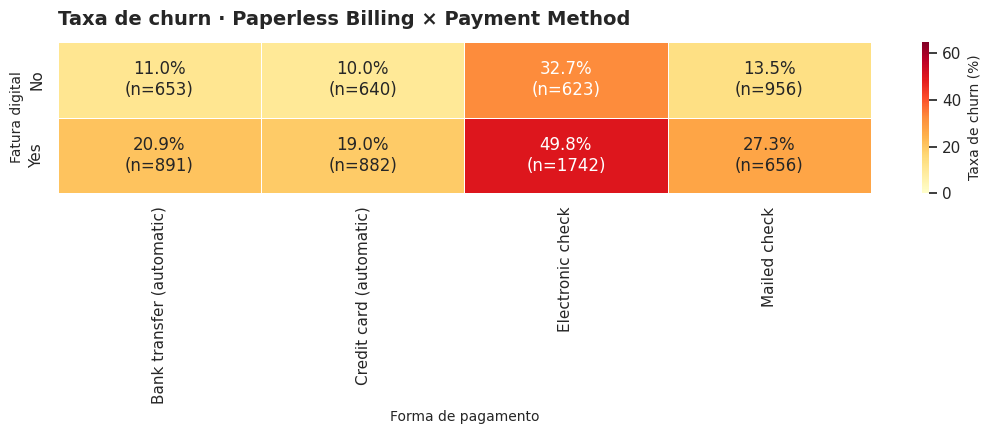

In [19]:
# Paperless Billing × Payment Method
rate_pp = df.pivot_table(index="Paperless Billing", columns="Payment Method", values="Churn Value", aggfunc="mean")
count_pp = df.pivot_table(index="Paperless Billing", columns="Payment Method", values="Churn Value", aggfunc="size")
annot_pp = rate_pp.mul(100).round(1).astype(str) + "%\n(n=" + count_pp.astype(int).astype(str) + ")"
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(rate_pp * 100, annot=annot_pp, fmt="", cmap="YlOrRd", vmin=0, vmax=65, linewidths=.6, linecolor="white", cbar_kws={"label": "Taxa de churn (%)"}, ax=ax)
ax.set_title("Taxa de churn · Paperless Billing × Payment Method", loc="left", pad=12)
ax.set_xlabel("Forma de pagamento")
ax.set_ylabel("Fatura digital")
plt.tight_layout()
plt.show()

## 9. Adoção de serviços adicionais

Os seis serviços abaixo são aplicáveis a clientes com internet. Por isso, a análise restringe explicitamente a população a `Internet Service != No`, evitando classificar `No internet service` como ausência voluntária de um adicional.

A variável de contagem representa quantos serviços adicionais (`Online Security`, `Online Backup`, `Device Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies`) estão marcados como `Yes`.

,Qtd Serviços Adicionais,clientes,cancelamentos,taxa_churn,ic95_inf,ic95_sup,taxa_churn_pct
0,0,693,362,0.522367,0.485156,0.559331,52.24
1,1,966,442,0.457557,0.426370,0.489080,45.76
2,2,1033,370,0.358180,0.329516,0.387895,35.82
3,3,1118,306,0.273703,0.248376,0.300580,27.37
4,4,852,190,0.223005,0.196332,0.252164,22.30
5,5,571,71,0.124343,0.099762,0.153945,12.43
6,6,284,15,0.052817,0.032265,0.085305,5.28


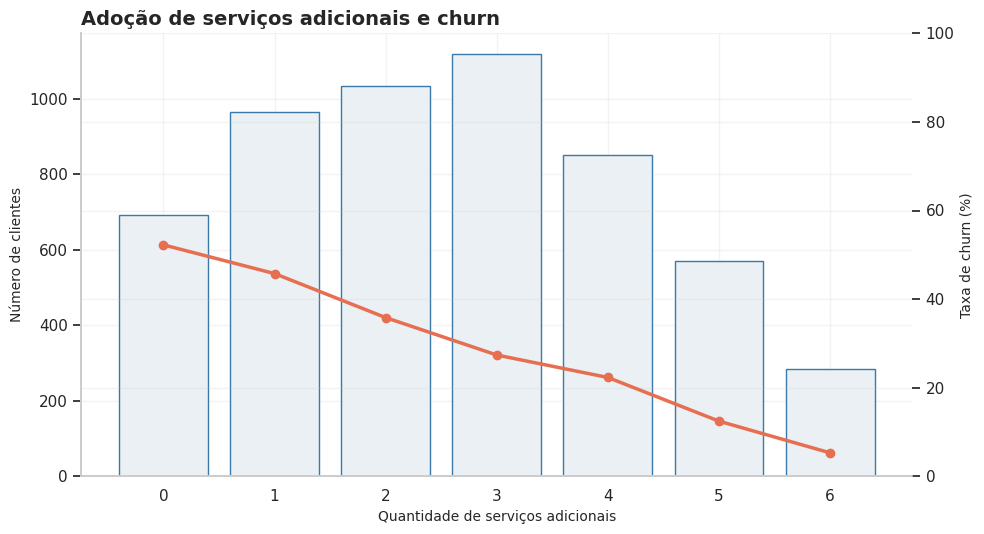

In [20]:
addon_cols = ["Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies"]
df_internet = df.loc[df["Internet Service"] != "No"].copy()
df_internet["Qtd Serviços Adicionais"] = df_internet[addon_cols].eq("Yes").sum(axis=1)

addon_summary = churn_summary(df_internet, "Qtd Serviços Adicionais")
display(addon_summary.assign(taxa_churn_pct=(addon_summary["taxa_churn"] * 100).round(2)))

fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax1.bar(addon_summary["Qtd Serviços Adicionais"].astype(str), addon_summary["clientes"], color=PALETTE["light"], edgecolor=PALETTE["blue"])
ax1.set_xlabel("Quantidade de serviços adicionais")
ax1.set_ylabel("Número de clientes")
ax2 = ax1.twinx()
ax2.plot(addon_summary["Qtd Serviços Adicionais"].astype(str), addon_summary["taxa_churn"] * 100, color=PALETTE["coral"], marker="o", lw=2.5)
ax2.set_ylabel("Taxa de churn (%)")
ax2.set_ylim(0, 100)
ax1.set_title("Adoção de serviços adicionais e churn", loc="left")
plt.tight_layout()
plt.show()

,Serviço,Assinatura,Clientes,Cancelamentos,Taxa de churn,IC95 inferior,IC95 superior,taxa_pct
0,Online Security,Possui,2019,295,0.146112,0.131377,0.162192,14.6
1,Online Security,Não possui,3498,1461,0.417667,0.401423,0.434092,41.8
2,Online Backup,Possui,2429,523,0.215315,0.199425,0.232104,21.5
3,Online Backup,Não possui,3088,1233,0.399288,0.382149,0.416676,39.9
4,Device Protection,Possui,2422,545,0.225021,0.208832,0.242080,22.5
5,Device Protection,Não possui,3095,1211,0.391276,0.374227,0.408595,39.1
6,Tech Support,Possui,2044,310,0.151663,0.136767,0.167866,15.2
7,Tech Support,Não possui,3473,1446,0.416355,0.400061,0.432833,41.6
8,Streaming TV,Possui,2707,814,0.300702,0.283720,0.318249,30.1
9,Streaming TV,Não possui,2810,942,0.335231,0.318012,0.352900,33.5


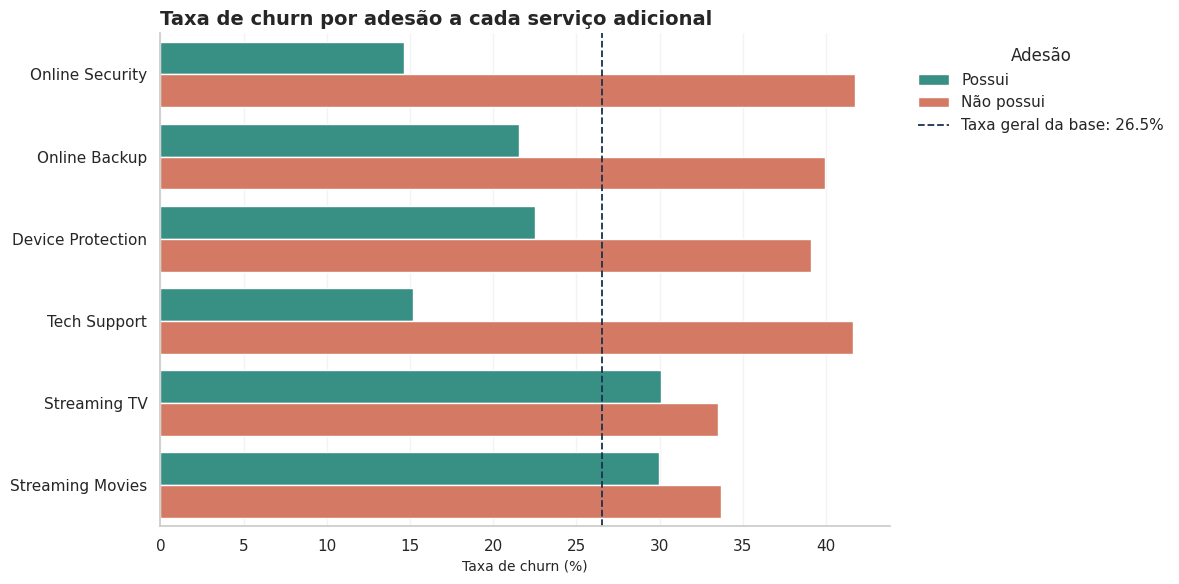

In [21]:
# Taxa de churn entre clientes com e sem cada adicional (somente clientes com internet)
addon_rows = []
for col in addon_cols:
    for status in ["Yes", "No"]:
        subset = df_internet.loc[df_internet[col] == status, "Churn Value"]
        lo, hi = wilson_interval(int(subset.sum()), len(subset))
        addon_rows.append({
            "Serviço": col,
            "Assinatura": "Possui" if status == "Yes" else "Não possui",
            "Clientes": len(subset),
            "Cancelamentos": int(subset.sum()),
            "Taxa de churn": subset.mean(),
            "IC95 inferior": lo,
            "IC95 superior": hi,
        })
addon_rates = pd.DataFrame(addon_rows)
display(addon_rates.assign(taxa_pct=(addon_rates["Taxa de churn"] * 100).round(1)))

fig, ax = plt.subplots(figsize=(12, 6))
plot_data = addon_rates.copy()
plot_data["Taxa (%)"] = plot_data["Taxa de churn"] * 100
sns.barplot(data=plot_data, x="Taxa (%)", y="Serviço", hue="Assinatura", palette={"Possui": PALETTE["teal"], "Não possui": PALETTE["coral"]}, ax=ax)
ax.axvline(churn_rate * 100, color=PALETTE["navy"], ls="--", lw=1.3, label=f"Taxa geral da base: {churn_rate:.1%}")
ax.set_title("Taxa de churn por adesão a cada serviço adicional", loc="left")
ax.set_xlabel("Taxa de churn (%)")
ax.set_ylabel("")
ax.legend(title="Adesão", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Ponto de interpretação:** menor churn entre clientes com mais serviços pode refletir maior integração do cliente ao ecossistema, mas também pode estar associado a tenure, contrato, preço ou perfil de cliente. O cruzamento é uma hipótese descritiva, não uma estimativa de efeito isolado dos serviços.

## 10. Cobranças e valor do cliente

Analisamos `Monthly Charges`, `Total Charges` e `CLTV` em conjunto. As faixas de cobrança são cortes exploratórios para facilitar a leitura; não representam limites comerciais oficiais.

,Monthly Charges Band,clientes,cancelamentos,taxa_churn,ic95_inf,ic95_sup,taxa_churn_pct
0,Até 30,1653,162,0.098004,0.084589,0.113283,9.80
1,30–50,646,199,0.308050,0.273668,0.344700,30.80
2,50–70,1161,241,0.207580,0.185233,0.231855,20.76
3,70–90,1844,697,0.377983,0.356126,0.400346,37.80
4,90–110,1524,542,0.355643,0.331999,0.380013,35.56
5,Acima de 110,215,28,0.130233,0.091662,0.181785,13.02


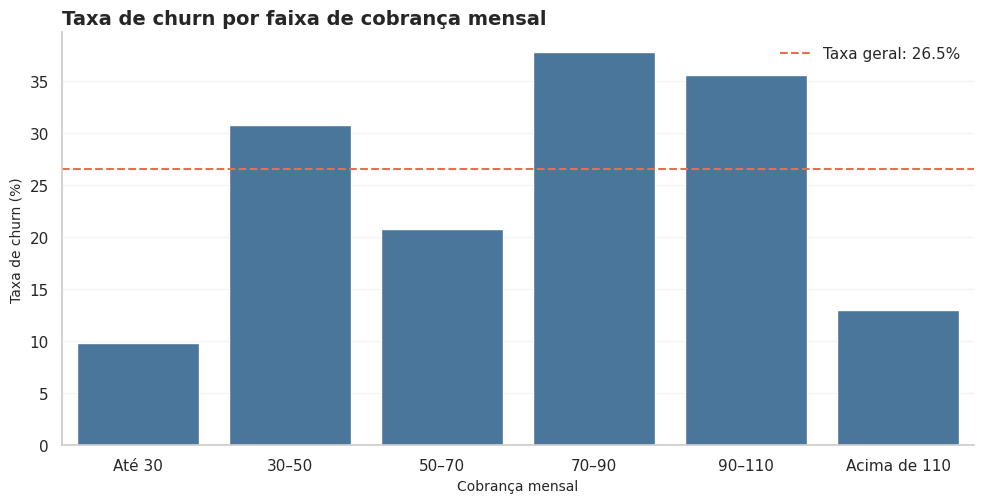

In [22]:
monthly_bins = [0, 30, 50, 70, 90, 110, 200]
monthly_labels = ["Até 30", "30–50", "50–70", "70–90", "90–110", "Acima de 110"]
df["Monthly Charges Band"] = pd.cut(df["Monthly Charges"], bins=monthly_bins, labels=monthly_labels, include_lowest=True)
monthly_summary = churn_summary(df, "Monthly Charges Band")
monthly_summary["Monthly Charges Band"] = pd.Categorical(monthly_summary["Monthly Charges Band"], categories=monthly_labels, ordered=True)
monthly_summary = monthly_summary.sort_values("Monthly Charges Band")
display(monthly_summary.assign(taxa_churn_pct=(monthly_summary["taxa_churn"] * 100).round(2)))

fig, ax = plt.subplots(figsize=(10, 5.2))
sns.barplot(data=monthly_summary, x="Monthly Charges Band", y=monthly_summary["taxa_churn"] * 100, color=PALETTE["blue"], ax=ax)
ax.axhline(churn_rate * 100, color=PALETTE["coral"], ls="--", lw=1.5, label=f"Taxa geral: {churn_rate:.1%}")
ax.set_title("Taxa de churn por faixa de cobrança mensal", loc="left")
ax.set_xlabel("Cobrança mensal")
ax.set_ylabel("Taxa de churn (%)")
ax.legend()
plt.tight_layout()
plt.show()

,CLTV Quartile,clientes,cancelamentos,taxa_churn,ic95_inf,ic95_sup,taxa_churn_pct
0,"(2002.999, 3469.0]",1763,607,0.344299,0.322480,0.366796,34.43
1,"(3469.0, 4527.0]",1759,472,0.268334,0.248149,0.289530,26.83
2,"(4527.0, 5380.5]",1760,425,0.241477,0.222059,0.262022,24.15
3,"(5380.5, 6500.0]",1761,365,0.207269,0.188983,0.226828,20.73


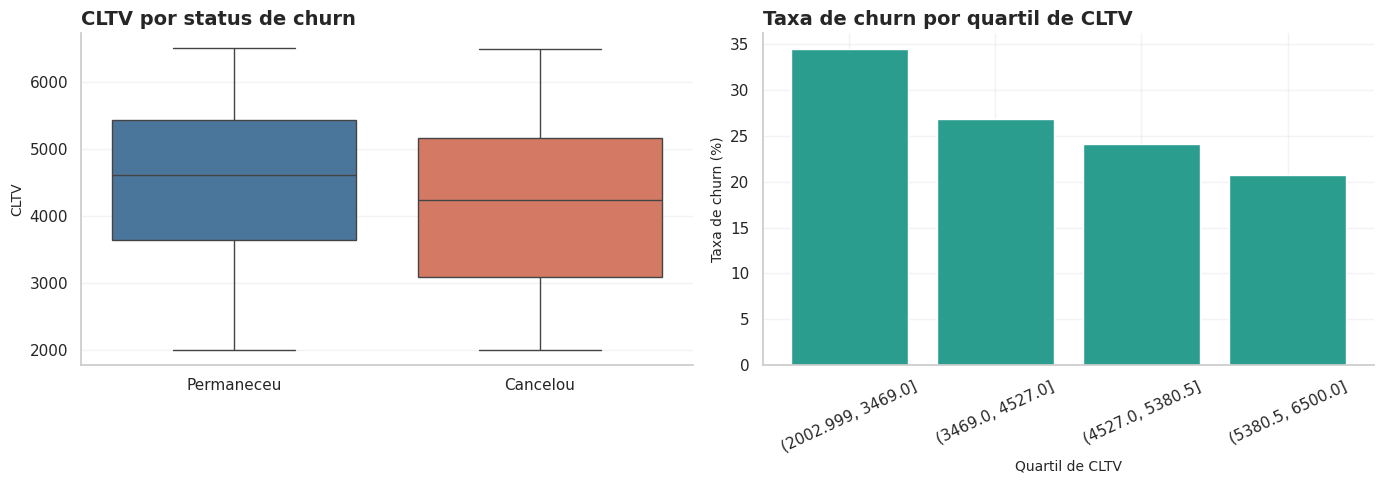

In [23]:
# CLTV por quartis: cortes calculados a partir da própria distribuição observada
# duplicates='drop' evita falha em caso de limites repetidos.
df["CLTV Quartile"] = pd.qcut(df["CLTV"], q=4, duplicates="drop")
cltv_summary = churn_summary(df, "CLTV Quartile")
display(cltv_summary.assign(taxa_churn_pct=(cltv_summary["taxa_churn"] * 100).round(2)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="Churn Status", y="CLTV", order=["Permaneceu", "Cancelou"], hue="Churn Status", dodge=False, palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]}, showfliers=False, legend=False, ax=axes[0])
axes[0].set_title("CLTV por status de churn", loc="left")
axes[0].set_xlabel("")
axes[1].bar(cltv_summary["CLTV Quartile"].astype(str), cltv_summary["taxa_churn"] * 100, color=PALETTE["teal"])
axes[1].set_title("Taxa de churn por quartil de CLTV", loc="left")
axes[1].set_xlabel("Quartil de CLTV")
axes[1].set_ylabel("Taxa de churn (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

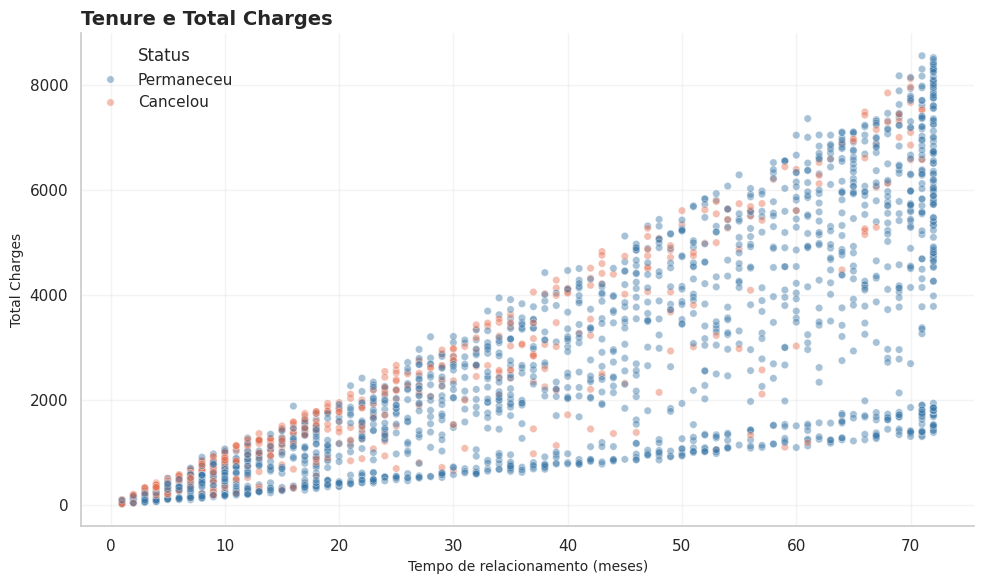

In [24]:
# Relação entre tenure e Total Charges; a correlação é apresentada como associação linear.
scatter_data = df.dropna(subset=["Tenure Months", "Total Charges Numeric"]).sample(
    n=min(2500, df["Total Charges Numeric"].notna().sum()), random_state=42
)
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=scatter_data, x="Tenure Months", y="Total Charges Numeric", hue="Churn Status", palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]}, alpha=0.45, s=28, ax=ax)
ax.set_title("Tenure e Total Charges", loc="left")
ax.set_xlabel("Tempo de relacionamento (meses)")
ax.set_ylabel("Total Charges")
ax.legend(title="Status")
plt.tight_layout()
plt.show()

## 11. Correlação entre variáveis numéricas

A matriz de correlação resume relações lineares entre variáveis numéricas. A correlação de `Total Charges` com `Tenure Months` é esperada em parte pela natureza acumulada da cobrança. Correlação não implica causalidade e não substitui a análise conjunta de variáveis categóricas.

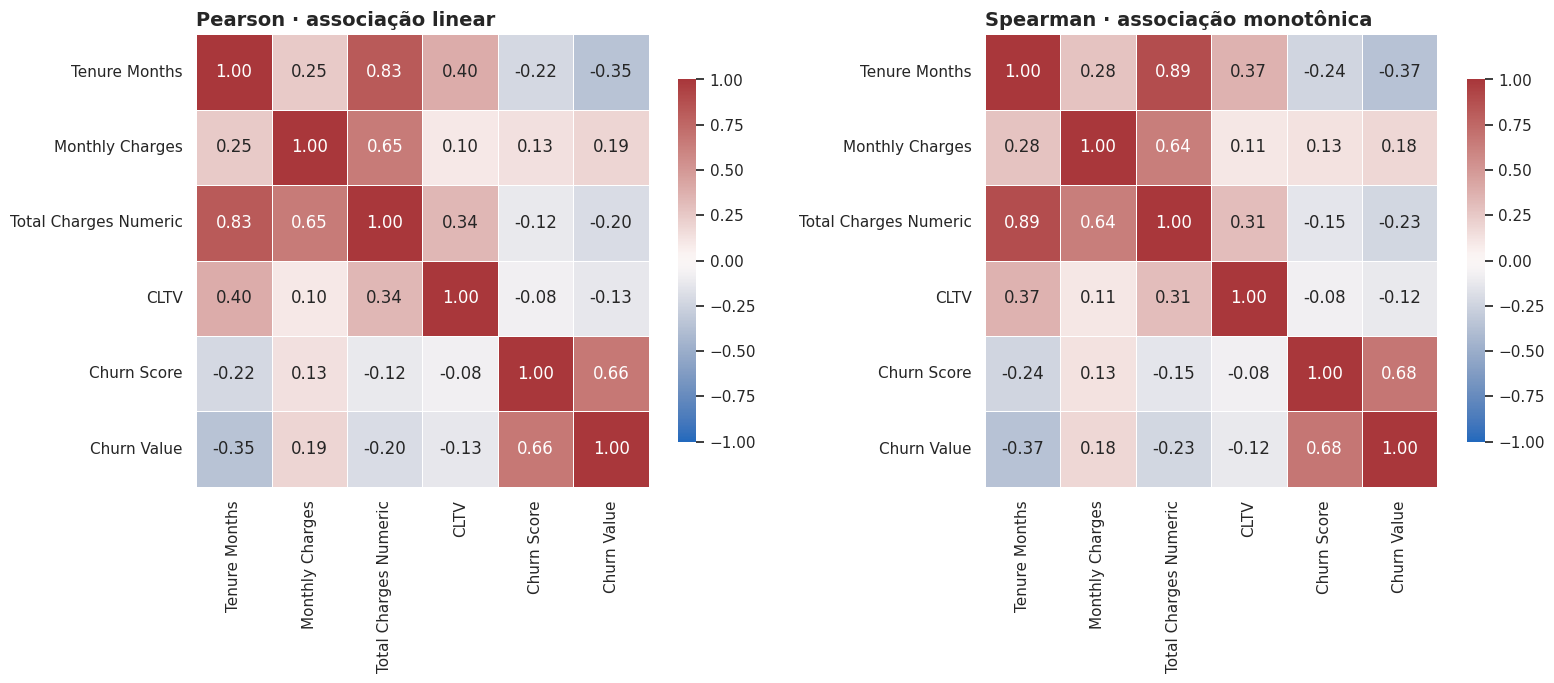

In [25]:
correlation_cols = ["Tenure Months", "Monthly Charges", "Total Charges Numeric", "CLTV", "Churn Score", "Churn Value"]
pearson_corr = df[correlation_cols].corr(method="pearson")
spearman_corr = df[correlation_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, corr, title in zip(axes, [pearson_corr, spearman_corr], ["Pearson · associação linear", "Spearman · associação monotônica"]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
    ax.set_title(title, loc="left")
plt.tight_layout()
plt.show()

## 12. Força de associação entre variáveis categóricas e churn

Além das taxas, o V de Cramér resume a força de associação entre uma variável categórica e o target binário. O indicador varia de 0 a 1; valores maiores representam associação mais forte na tabela de contingência.

Os p-valores do qui-quadrado são apresentados como complemento, mas devem ser interpretados com cautela: com amostras grandes, diferenças pequenas podem se tornar estatisticamente significativas. A magnitude do efeito e o contexto de negócio são mais importantes do que um corte isolado de significância.

,Variável,V de Cramér,p-valor (qui-quadrado)
13,Contract,0.410,5.86e-258
7,Online Security,0.347,2.66e-185
10,Tech Support,0.343,1.44e-180
6,Internet Service,0.322,9.57e-160
15,Payment Method,0.303,3.68e-140
8,Online Backup,0.292,2.08e-131
9,Device Protection,0.281,5.51e-122
3,Dependents,0.248,1.28e-96
12,Streaming Movies,0.230,2.67e-82
11,Streaming TV,0.230,5.53e-82


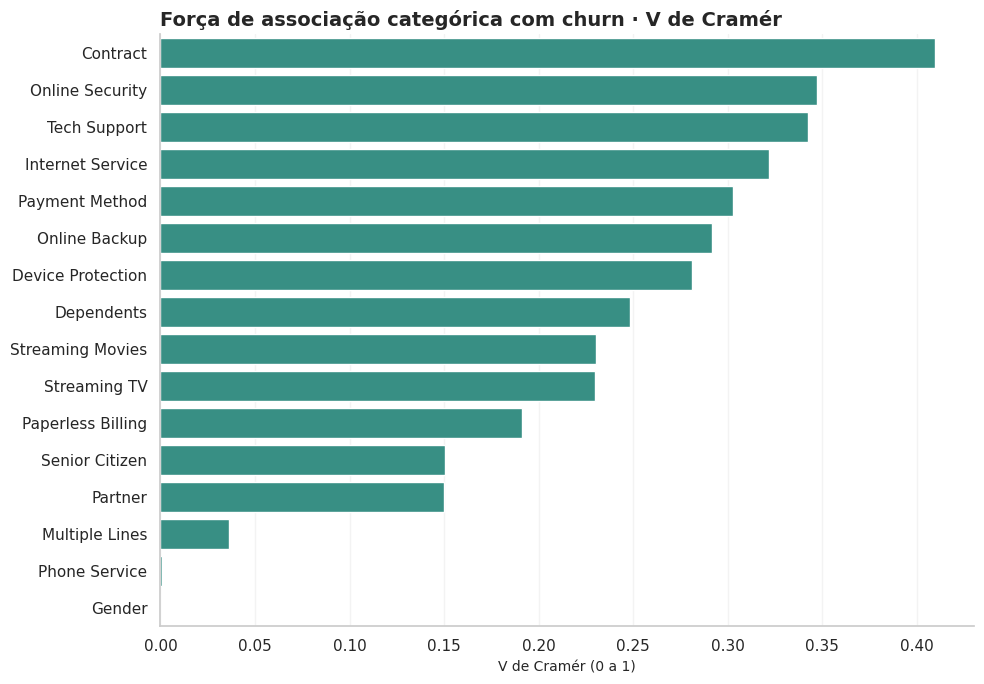

In [26]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.empty or min(table.shape) < 2:
        return np.nan, np.nan
    chi2, p_value, _, _ = chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    r, k = table.shape
    # Correção de viés de Bergsma (reduz viés em tabelas finitas)
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / max(n - 1, 1))
    r_corr = r - ((r - 1) ** 2) / max(n - 1, 1)
    k_corr = k - ((k - 1) ** 2) / max(n - 1, 1)
    denom = min(k_corr - 1, r_corr - 1)
    v = np.sqrt(phi2_corr / denom) if denom > 0 else np.nan
    return v, p_value

categorical_candidates = [
    "Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service",
    "Multiple Lines", "Internet Service", "Online Security", "Online Backup",
    "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method"
]
association_rows = []
for col in categorical_candidates:
    v, p = cramers_v(df[col], df["Churn Value"])
    association_rows.append({"Variável": col, "V de Cramér": v, "p-valor (qui-quadrado)": p})
association = pd.DataFrame(association_rows).sort_values("V de Cramér", ascending=False)
display(association.style.format({"V de Cramér": "{:.3f}", "p-valor (qui-quadrado)": "{:.2e}"}).background_gradient(subset=["V de Cramér"], cmap="Blues"))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(data=association, x="V de Cramér", y="Variável", color=PALETTE["teal"], ax=ax)
ax.set_title("Força de associação categórica com churn · V de Cramér", loc="left")
ax.set_xlabel("V de Cramér (0 a 1)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 13. Motivos de cancelamento

Esta seção considera exclusivamente os clientes com `Churn Value = 1`. A categoria é derivada de `Churn Reason` com o agrupamento conceitual adotado na análise inicial. O percentual de cada motivo usa como denominador os **1.869 cancelamentos**, não toda a base.

Todos os motivos observados entre os cancelados foram mapeados.


,Cancelamentos,Participação nos cancelamentos
Categoria,,
Concorrência,621,33.2%
Qualidade do Produto e Rede,426,22.8%
Atendimento ao Cliente,366,19.6%
Preço e Cobranças,243,13.0%
Desconhecido,154,8.2%
Motivos Pessoais,59,3.2%


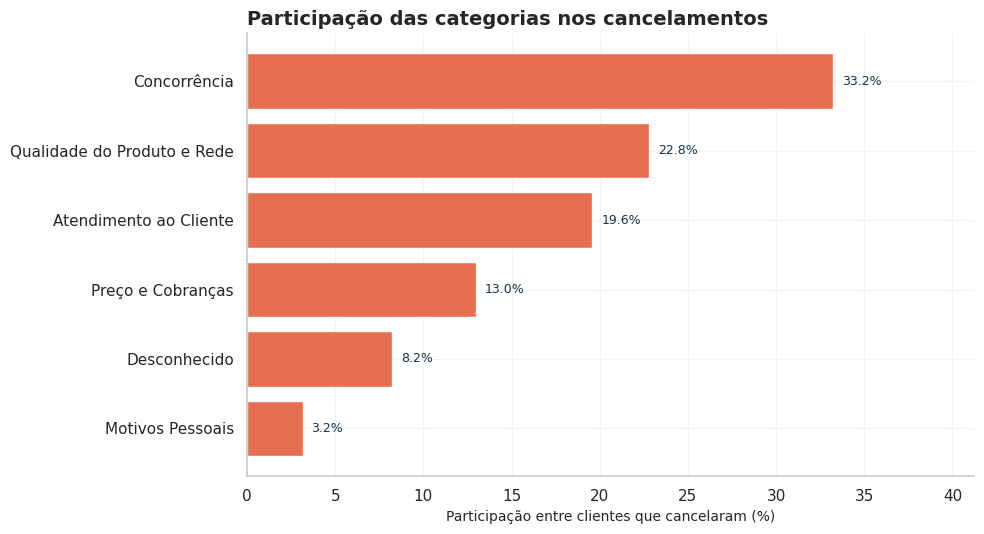

In [27]:
reason_mapping = {
    # Concorrência
    "Competitor offered higher download speeds": "Concorrência",
    "Competitor offered more data": "Concorrência",
    "Competitor made better offer": "Concorrência",
    "Competitor had better devices": "Concorrência",
    # Atendimento
    "Attitude of support person": "Atendimento ao Cliente",
    "Attitude of service provider": "Atendimento ao Cliente",
    "Poor expertise of phone support": "Atendimento ao Cliente",
    "Poor expertise of online support": "Atendimento ao Cliente",
    # Produto e rede
    "Network reliability": "Qualidade do Produto e Rede",
    "Product dissatisfaction": "Qualidade do Produto e Rede",
    "Service dissatisfaction": "Qualidade do Produto e Rede",
    "Lack of self-service on Website": "Qualidade do Produto e Rede",
    "Limited range of services": "Qualidade do Produto e Rede",
    # Preço e cobrança
    "Price too high": "Preço e Cobranças",
    "Extra data charges": "Preço e Cobranças",
    "Long distance charges": "Preço e Cobranças",
    "Lack of affordable download/upload speed": "Preço e Cobranças",
    # Pessoais
    "Moved": "Motivos Pessoais",
    "Deceased": "Motivos Pessoais",
    # Desconhecido
    "Don't know": "Desconhecido",
}

churned = df.loc[df["Churn Value"] == 1].copy()
churned["Churn Category"] = churned["Churn Reason"].map(reason_mapping)

unmapped = churned.loc[churned["Churn Category"].isna(), "Churn Reason"].value_counts(dropna=False)
if not unmapped.empty:
    print("Atenção: motivos sem mapeamento:")
    display(unmapped.to_frame("quantidade"))
else:
    print("Todos os motivos observados entre os cancelados foram mapeados.")

reason_category = (
    churned["Churn Category"].value_counts(dropna=False)
    .rename_axis("Categoria")
    .to_frame("Cancelamentos")
)
reason_category["Participação nos cancelamentos"] = reason_category["Cancelamentos"] / len(churned)
display(reason_category.style.format({"Participação nos cancelamentos": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_reason = reason_category.sort_values("Cancelamentos")
ax.barh(plot_reason.index, plot_reason["Participação nos cancelamentos"] * 100, color=PALETTE["coral"])
for y, value in enumerate(plot_reason["Participação nos cancelamentos"] * 100):
    ax.text(value + 0.5, y, f"{value:.1f}%", va="center", fontsize=9, color=PALETTE["navy"])
ax.set_title("Participação das categorias nos cancelamentos", loc="left")
ax.set_xlabel("Participação entre clientes que cancelaram (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(plot_reason["Participação nos cancelamentos"] * 100) + 8)
plt.tight_layout()
plt.show()

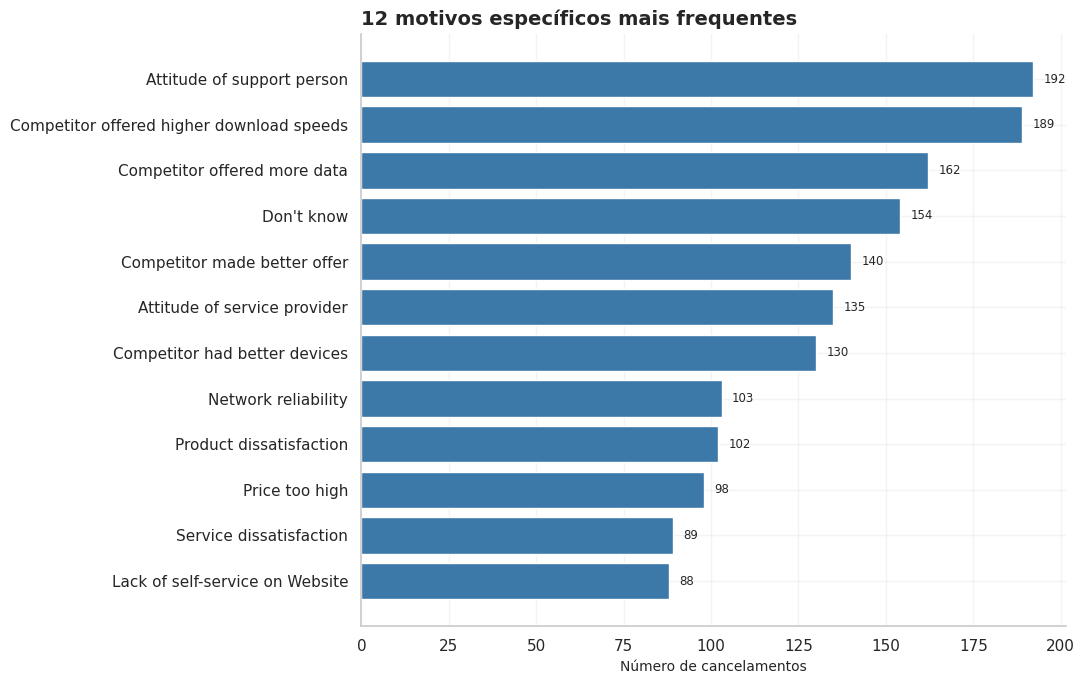

In [28]:
# Motivos individuais mais frequentes
reason_detail = churned["Churn Reason"].value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(reason_detail.index, reason_detail.values, color=PALETTE["blue"])
for y, value in enumerate(reason_detail.values):
    ax.text(value + 3, y, f"{value:,}", va="center", fontsize=8.5)
ax.set_title("12 motivos específicos mais frequentes", loc="left")
ax.set_xlabel("Número de cancelamentos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 13.1 Composição dos motivos por tipo de internet e contrato

Os gráficos abaixo respondem: **entre os clientes que cancelaram por determinada categoria, como se distribuem os tipos de internet e os contratos?** Eles não representam taxa de churn por contrato ou por serviço; representam composição dentro do subconjunto de cancelados.

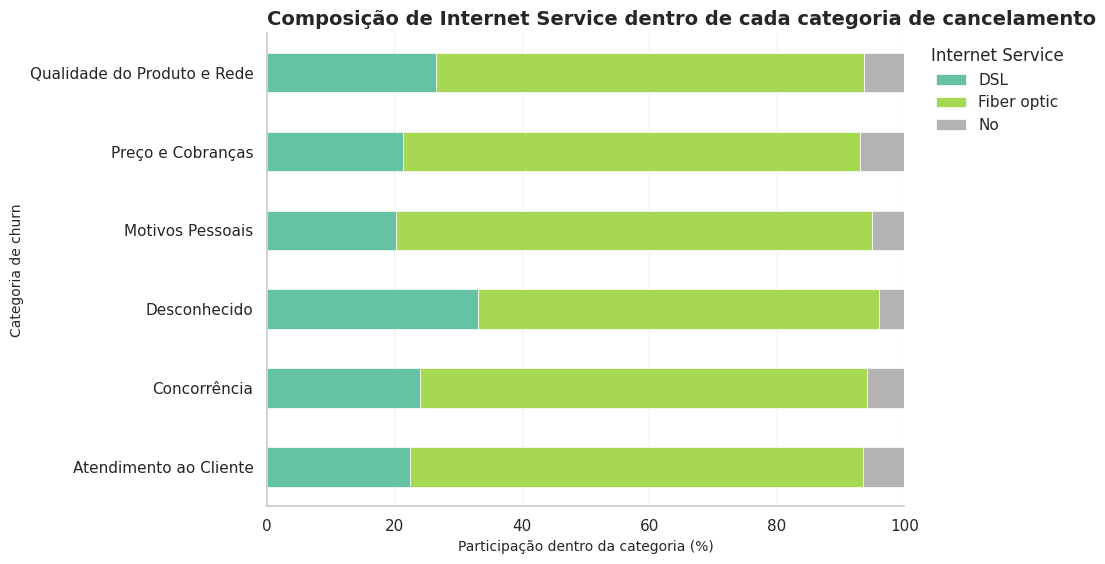

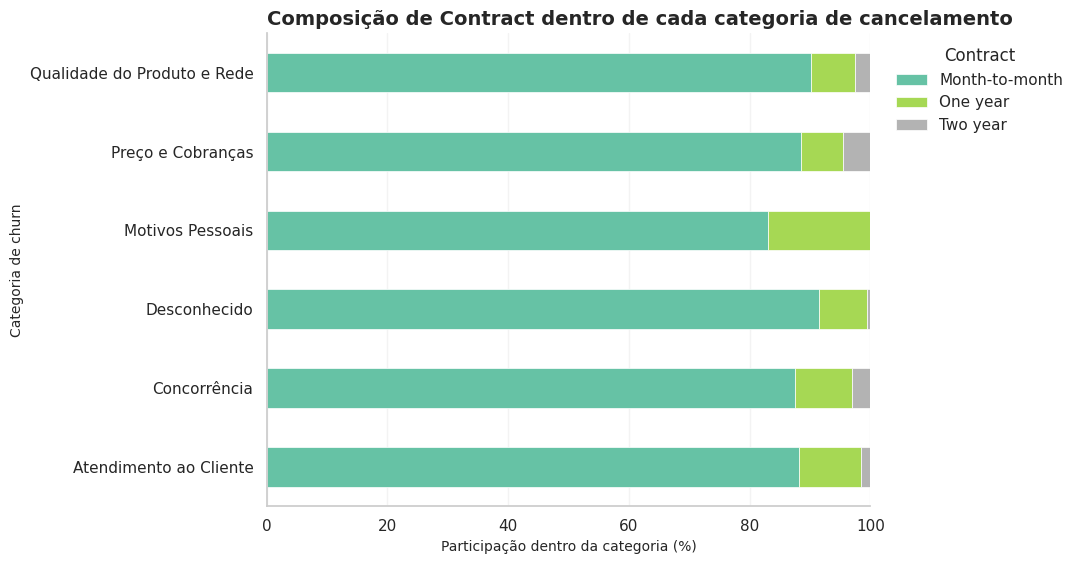

In [29]:
for col in ["Internet Service", "Contract"]:
    composition = pd.crosstab(churned["Churn Category"], churned[col], normalize="index") * 100
    ax = composition.plot(kind="barh", stacked=True, figsize=(11, 5.8), colormap="Set2", edgecolor="white", linewidth=.5)
    ax.set_title(f"Composição de {col} dentro de cada categoria de cancelamento", loc="left")
    ax.set_xlabel("Participação dentro da categoria (%)")
    ax.set_ylabel("Categoria de churn")
    ax.set_xlim(0, 100)
    ax.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

## 14. Dimensão geográfica

A base possui muitas cidades com poucos registros. Por esse motivo, a comparação será limitada a cidades com pelo menos 20 clientes e apresentará taxa, volume e intervalo de confiança. O filtro é um critério operacional para reduzir ruído, não uma garantia de representatividade estatística.

In [30]:
city_summary = churn_summary(df, "City", min_n=20)
city_summary = city_summary.sort_values("taxa_churn", ascending=False)
print(f"Cidades distintas na base: {df['City'].nunique():,}")
print(f"Cidades com pelo menos 20 clientes: {(df['City'].value_counts() >= 20).sum():,}")
print(f"Clientes considerados após o filtro: {city_summary['clientes'].sum():,} de {len(df):,}")

display(city_summary.head(15).assign(
    taxa_churn_pct=(city_summary.head(15)["taxa_churn"] * 100).round(1),
    ic95=(city_summary.head(15)["ic95_inf"].map(lambda x: f"{x:.1%}") + " – " + city_summary.head(15)["ic95_sup"].map(lambda x: f"{x:.1%}"))
)[["City", "clientes", "cancelamentos", "taxa_churn_pct", "ic95"]])

Cidades distintas na base: 1,129
Cidades com pelo menos 20 clientes: 35
Clientes considerados após o filtro: 1,676 de 7,043


,City,clientes,cancelamentos,taxa_churn_pct,ic95
908,Santa Rosa,24,11,45.8,27.9% – 64.9%
688,North Hollywood,20,9,45.0,25.8% – 65.8%
632,Modesto,28,12,42.9,26.5% – 60.9%
899,Santa Barbara,28,10,35.7,20.7% – 54.2%
869,San Diego,150,50,33.3,26.3% – 41.2%
371,Glendale,40,13,32.5,20.1% – 48.0%
1019,Torrance,25,8,32.0,17.2% – 51.6%
748,Pasadena,30,9,30.0,16.7% – 47.9%
872,San Francisco,104,31,29.8,21.9% – 39.2%
562,Los Angeles,305,90,29.5,24.7% – 34.9%


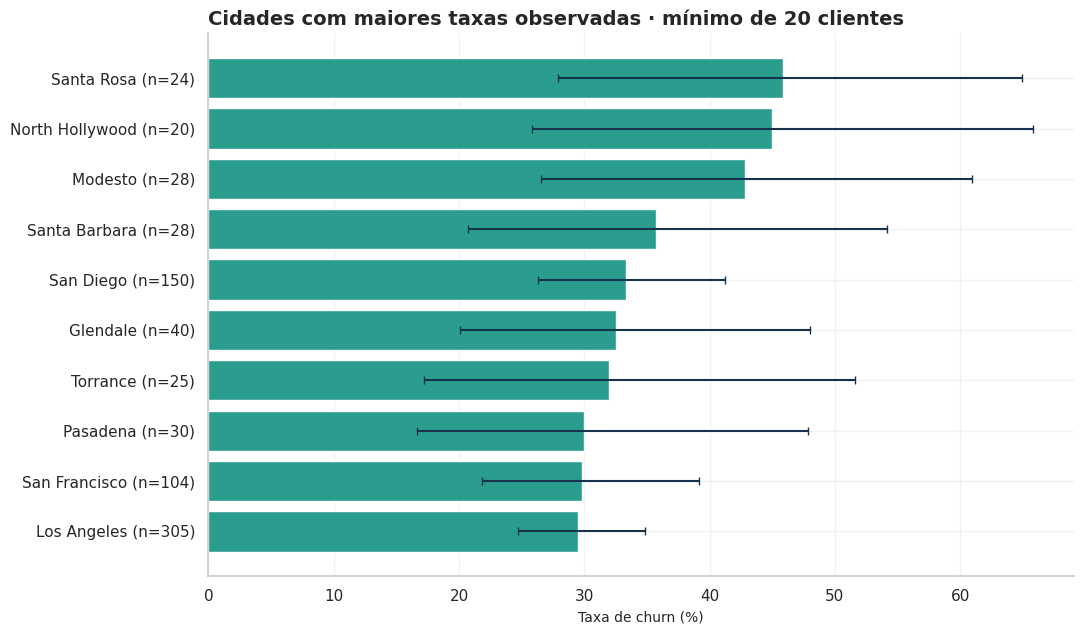

In [31]:
# Dez maiores taxas entre cidades com n >= 20; rótulos exibem também o tamanho da base.
city_top = city_summary.head(10).sort_values("taxa_churn")
fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(city_top))
rates = city_top["taxa_churn"].to_numpy()
lo = rates - city_top["ic95_inf"].to_numpy()
hi = city_top["ic95_sup"].to_numpy() - rates
ax.barh(y, rates * 100, color=PALETTE["teal"])
ax.errorbar(rates * 100, y, xerr=np.vstack([lo, hi]) * 100, fmt="none", ecolor=PALETTE["navy"], capsize=3)
ax.set_yticks(y, [f"{c} (n={n})" for c, n in zip(city_top["City"], city_top["clientes"])])
ax.set_xlabel("Taxa de churn (%)")
ax.set_title("Cidades com maiores taxas observadas · mínimo de 20 clientes", loc="left")
plt.tight_layout()
plt.show()

**Limitação geográfica:** a base contém 1.129 cidades, mas somente 35 alcançam o mínimo de 20 clientes. Rankings de cidades pequenas podem variar muito com poucos registros; por isso, a análise geográfica deve ser tratada como exploratória e não como evidência de diferença estrutural entre localidades.

## 15. Leitura crítica de Churn Score

O dicionário da base descreve `Churn Score` como uma pontuação de 0 a 100 calculada por uma ferramenta preditiva IBM SPSS Modeler, incorporando fatores associados ao cancelamento. Por essa origem, sua relação com o target merece leitura separada: ele não é uma variável operacional bruta equivalente a contrato ou forma de pagamento.

,clientes,média,mediana,mínimo,máximo
Churn Status,,,,,
Cancelou,1869,82.51,82.0,65,100
Permaneceu,5174,50.10,50.0,5,80


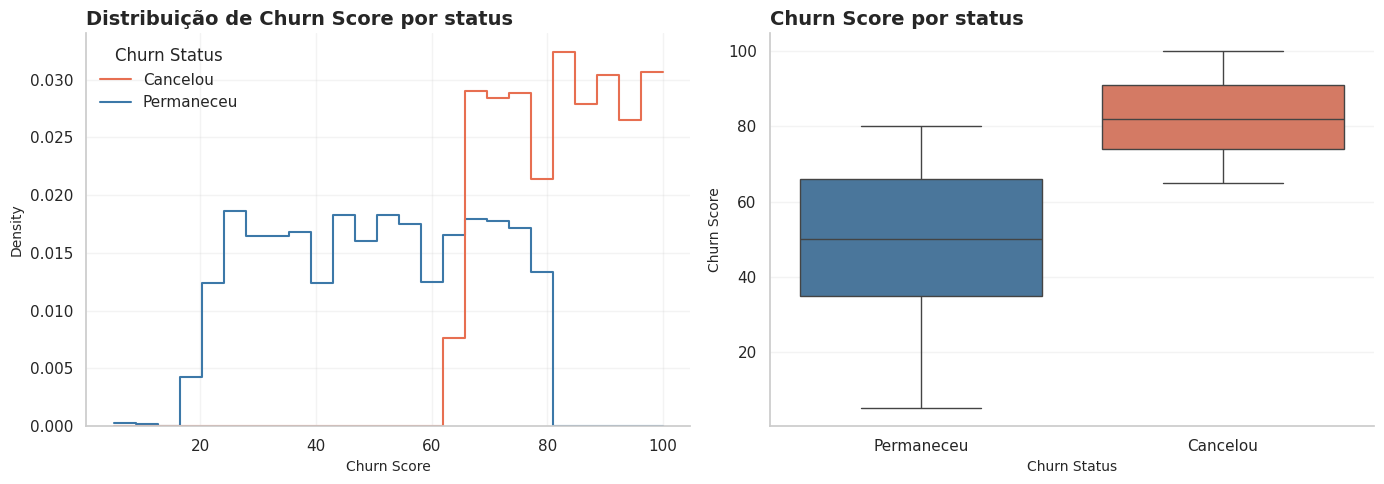

,min,max,mean,median
Churn Value,,,,
0,5,80,50.098183,50.0
1,65,100,82.510433,82.0


In [32]:
score_summary = df.groupby("Churn Status")["Churn Score"].agg(
    clientes="count", média="mean", mediana="median", mínimo="min", máximo="max"
)
display(score_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="Churn Score", hue="Churn Status", stat="density", common_norm=False, bins=25, element="step", fill=False, palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]}, ax=axes[0])
axes[0].set_title("Distribuição de Churn Score por status", loc="left")
sns.boxplot(data=df, x="Churn Status", y="Churn Score", order=["Permaneceu", "Cancelou"], hue="Churn Status", dodge=False, palette={"Permaneceu": PALETTE["blue"], "Cancelou": PALETTE["coral"]}, showfliers=False, legend=False, ax=axes[1])
axes[1].set_title("Churn Score por status", loc="left")
plt.tight_layout()
plt.show()

score_ranges = df.groupby("Churn Value")["Churn Score"].agg(["min", "max", "mean", "median"])
display(score_ranges)

**Cautela:** uma separação muito forte entre `Churn Score` e `Churn Value` pode refletir a proximidade conceitual entre o score e o próprio evento de cancelamento. Sem documentação sobre a data de cálculo e os dados usados pelo score, não é possível concluir que ele represente uma informação independente e disponível antes do evento. Nesta EDA, ele é tratado como variável derivada/externa e analisado com essa ressalva.

## 16. Síntese dos principais achados

Esta seção consolida os padrões observados ao longo da exploração. Os valores são calculados diretamente da base carregada, evitando copiar números manualmente para o relatório.

In [33]:
# Tabelas auxiliares para síntese dinâmica
contract_rates = churn_summary(df, "Contract").set_index("Contract")
payment_rates = churn_summary(df, "Payment Method").set_index("Payment Method")
internet_rates = churn_summary(df, "Internet Service").set_index("Internet Service")
dependents_rates = churn_summary(df, "Dependents").set_index("Dependents")

contract_month = float(contract_rates.loc["Month-to-month", "taxa_churn"])
contract_two_year = float(contract_rates.loc["Two year", "taxa_churn"])
electronic_check = float(payment_rates.loc["Electronic check", "taxa_churn"])
fiber_rate = float(internet_rates.loc["Fiber optic", "taxa_churn"])
no_dependents_rate = float(dependents_rates.loc["No", "taxa_churn"])
with_dependents_rate = float(dependents_rates.loc["Yes", "taxa_churn"])

# Categoria de motivo mais frequente entre churners
most_common_reason_group = reason_category.index[0]
most_common_reason_share = reason_category.iloc[0]["Participação nos cancelamentos"]

summary_html = f"""
<div style='background:#F2F6F9;border-radius:10px;padding:18px 22px;border-left:5px solid #17324D;line-height:1.65'>
<b>Resumo quantitativo da base</b><br>
• A taxa geral de churn é <b>{churn_rate:.1%}</b> ({n_churn:,} de {n_total:,} clientes).<br>
• Contratos mensais apresentam churn de <b>{contract_month:.1%}</b>, enquanto contratos de dois anos apresentam <b>{contract_two_year:.1%}</b>.<br>
• A taxa observada entre clientes que pagam por cheque eletrônico é <b>{electronic_check:.1%}</b>.<br>
• Clientes com fibra óptica apresentam churn de <b>{fiber_rate:.1%}</b>.<br>
• A taxa observada é <b>{no_dependents_rate:.1%}</b> para clientes sem dependentes e <b>{with_dependents_rate:.1%}</b> para clientes com dependentes.<br>
• A categoria mais frequente entre os motivos informados é <b>{most_common_reason_group}</b> ({most_common_reason_share:.1%} dos cancelamentos).
</div>
"""
display(HTML(summary_html))

### Hipóteses de negócio sugeridas pela EDA

1. **Flexibilidade contratual:** o churn está concentrado em contratos mensais. Investigar jornadas de migração para contratos mais longos, sem assumir que o contrato por si só causa a retenção.
2. **Experiência de pagamento:** a forma de pagamento `Electronic check` apresenta taxa elevada. Investigar fricção no processo de pagamento, inadimplência, preferências e perfil dos clientes desse grupo.
3. **Proposta de valor da fibra:** clientes de fibra óptica apresentam maior churn que DSL e clientes sem internet. Cruzar esse achado com qualidade percebida, preço, suporte e concorrência.
4. **Adoção de serviços complementares:** a taxa observada diminui à medida que aumenta o número de adicionais entre clientes com internet. Avaliar se essa associação permanece dentro de faixas comparáveis de tenure e contrato.
5. **Experiência nos primeiros meses:** clientes com pouco tempo de relacionamento e contrato mensal apresentam taxas elevadas. Investigar onboarding, instalação, expectativa de serviço e primeiros contatos de suporte.
6. **Concorrência e qualidade:** concorrência, qualidade/rede e atendimento aparecem como categorias frequentes entre as razões informadas. Avaliar ações específicas por motivo, sem generalizar a partir de categorias agregadas.

### Limitações desta exploração

- A base representa uma fotografia de um trimestre; não temos a sequência temporal completa das interações e mudanças contratuais.
- Taxas de churn são associações descritivas e podem refletir composição de grupos e variáveis correlacionadas.
- `Churn Reason` é observado após o cancelamento e descreve o motivo informado; não deve ser confundido com antecedente do evento.
- `Churn Score` e `CLTV` são variáveis derivadas conforme o dicionário original; origem, data de cálculo e disponibilidade precisam ser conhecidas para interpretações causais ou temporais.
- A geografia possui alta cardinalidade e grande número de cidades com poucos registros.
- A análise de `Total Charges` preserva os 11 valores não informados, todos associados a tenure zero; não foi feita imputação arbitrária.

---

**Encerramento da EDA**  
A exploração identificou segmentos com taxas de churn substancialmente distintas e hipóteses de negócio que merecem validação adicional. As conclusões devem ser entendidas como descritivas, dentro do universo e do período representados pelo dataset.